In [193]:
import pandas as pd
import numpy as np
import sys
import os
import matplotlib.pyplot as plt

In [194]:
d = pd.read_excel(r"E:\aug-2025\Introduction-mms\project-2\cityData\Project 2_Metro Station Survey Data.xlsx", sheet_name="Bengaluru")
location = pd.read_csv(r"E:\aug-2025\Introduction-mms\project-2\cityData\Bengaluru metro locations.csv")

location.head()


,"Name,C,254","Latitude,N,19,11","Longitude,N,19,11"
0,Whitefield (Kadugodi),12.995646,77.757859
1,Hopefarm Channasandra,12.987113,77.753758
2,Kadugodi Tree Park,12.985677,77.747026
3,Pattandur Agrahara,12.987639,77.737772
4,Sathya Sai Hospital,12.981195,77.727536


Number of null values in 'Metro Station at which the survey is being conducted': 0
Metro Station at which the survey is being conducted
Indiranagar        425
Banashankari       404
Baiyappanahalli    386
Yeshwantpur        341
Cubbon Park        328
Nayandahalli       321
Name: count, dtype: int64


<Axes: xlabel='Metro Station at which the survey is being conducted'>

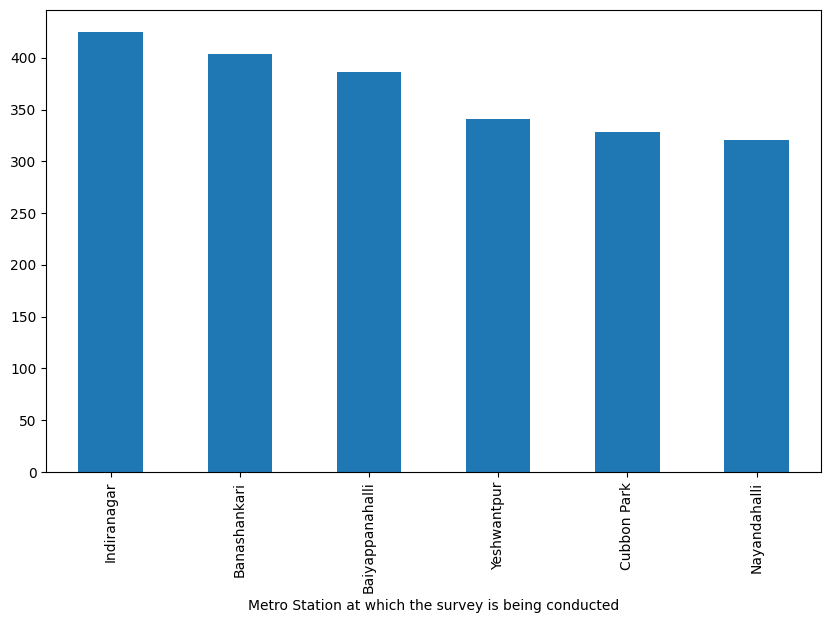

In [195]:
# Metro Station at which the survey is being conducted

column_name_metro_station = 'Metro Station at which the survey is being conducted'
# Null values in metro station
null_values_metro_station = d[column_name_metro_station].isnull().sum()
print(f"Number of null values in 'Metro Station at which the survey is being conducted': {null_values_metro_station}")

# Value counts in metro station
print(d[column_name_metro_station].value_counts())

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_metro_station].value_counts().plot(kind='bar')

In [196]:
# Location within station where survey is being conducted (example – entry gate/exit gate/platform).
column_name_location_within_station = 'Location within station where survey is being conducted (example – entry gate/exit gate/platform).'

# Which is the **Origin** metro station of this trip? / Which is the **Destination** metro station of this trip?
column_name_origin_destination = 'Which is the **Origin** metro station of this trip? / Which is the **Destination** metro station of this trip?'


old_names = d[column_name_origin_destination].unique().tolist()
sorted_old_names = sorted(old_names)
print(len(old_names))
print(len(sorted_old_names))
new_names = location['Name,C,254'].unique().tolist()
sorted_new_names = sorted(new_names)
print(len(new_names))

import rapidfuzz
from rapidfuzz import process, fuzz

correct_names = location['Name,C,254'].unique()

def correct_name(wrong):
    match, score, _ = process.extractOne(wrong, correct_names, scorer=fuzz.ratio)
    return match if score > 50 else wrong   # threshold 80% similarity

d[column_name_origin_destination] = d[column_name_origin_destination].apply(correct_name)

print(len(d[column_name_origin_destination].unique().tolist()))
print(location.columns.tolist())
d = d.merge(location, left_on=column_name_origin_destination, right_on='Name,C,254', how='left')
d.drop(columns=['Name,C,254'], inplace=True)
d.rename(columns={'Latitude,N,19,11': 'Latitude', 'Longitude,N,19,11': 'Longitude'}, inplace=True)
print(d['Longitude'].isnull().sum())
print(d['Latitude'].isnull().sum())



51
51
63
50
['Name,C,254', 'Latitude,N,19,11', 'Longitude,N,19,11']
0
0


In [197]:
# Origin and Destination metro station

d['Origin Station'] = d.apply(lambda row: row[column_name_metro_station] if 'Entry Gate' in row[column_name_location_within_station] else row[column_name_origin_destination], axis=1)
d['Destination Station'] = d.apply(lambda row: row[column_name_metro_station] if 'Exit Gate' in row[column_name_location_within_station] else row[column_name_origin_destination], axis=1)



Number of null values in 'Frequency of the trip': 0
['>5 Times A Week' '3-5 Times A Week' '1-2 Times A Week']
Frequency of the trip
3-5 Times A Week    1221
>5 Times A Week      808
1-2 Times A Week     176
Name: count, dtype: int64


<Axes: xlabel='Frequency of the trip'>

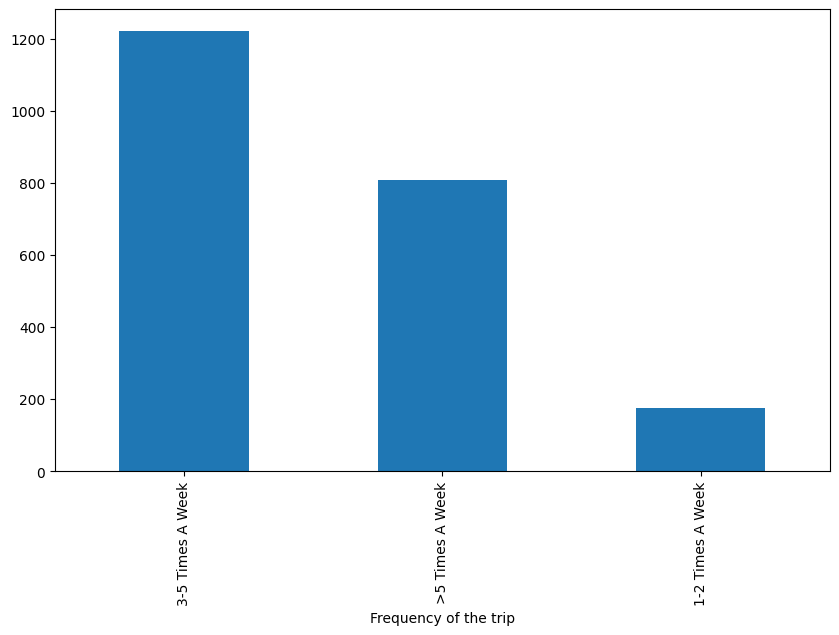

In [198]:
# Frequency of the trip
column_name_frequency_of_trip = 'Frequency of the trip'
# Null values in frequency of trip
null_values_frequency_of_trip = d[column_name_frequency_of_trip].isnull().sum()
print(f"Number of null values in 'Frequency of the trip': {null_values_frequency_of_trip}")

# unique values frequency of trip
print(d[column_name_frequency_of_trip].unique())

# value counts frequency of trip
print(d[column_name_frequency_of_trip].value_counts())

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_frequency_of_trip].value_counts().plot(kind='bar')

Number of null values in 'Purpose of the trip': 0
['Educational (Visit School, College, Etc.)' 'Work'
 'Social (Visit Friend, Relative, Etc.)'
 'Health (Visit Hospital, Clinic, Etc.)'
 'Recreational (Visit Movie Theatre, Shopping Mall, Etc.)'
 'Shopping (Visit Supermarket, Mandis, Shopping Mall, Etc.)'
 'Transportation Hub(Visit Airport, Railway St., Bus Terminus, Etc.)(Respondent To Provide Name Of The Transportation Hub)']
purpose of this trip
Work         1510
Education     475
Outing        183
Others         37
Name: count, dtype: int64


<Axes: xlabel='purpose of this trip'>

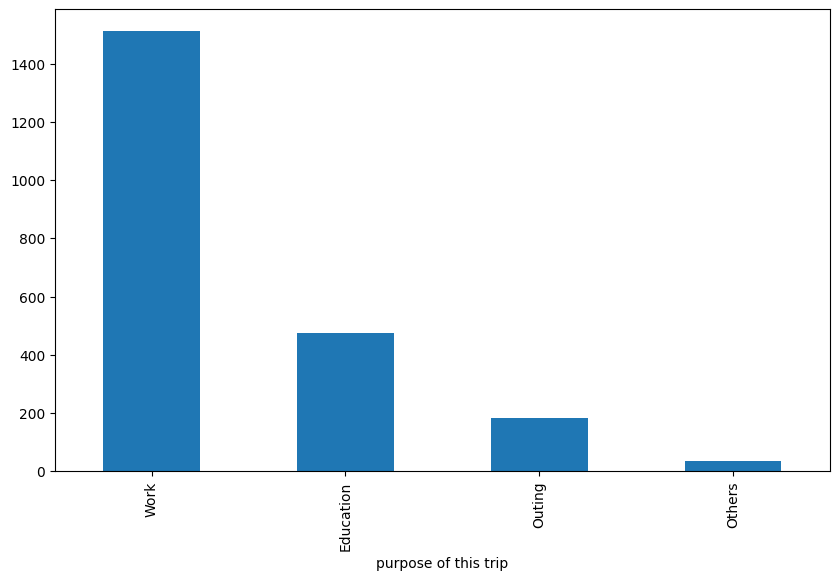

In [199]:
# purpose of this trip
column_name_purpose_of_trip = 'purpose of this trip'
# Null values in purpose of trip
null_values_purpose_of_trip = d[column_name_purpose_of_trip].isnull().sum()
print(f"Number of null values in 'Purpose of the trip': {null_values_purpose_of_trip}")

# unique values purpose of trip
print(d[column_name_purpose_of_trip].unique())

mapping = {'Educational (Visit School, College, Etc.)': 'Education',
           'Work': 'Work',
           'Social (Visit Friend, Relative, Etc.)': 'Outing',
           'Health (Visit Hospital, Clinic, Etc.)': 'Others',
           'Recreational (Visit Movie Theatre, Shopping Mall, Etc.)': 'Outing',
           'Shopping (Visit Supermarket, Mandis, Shopping Mall, Etc.)': 'Outing',
           'Transportation Hub(Visit Airport, Railway St., Bus Terminus, Etc.)(Respondent To Provide Name Of The Transportation Hub)': 'Others'}

d[column_name_purpose_of_trip] = d[column_name_purpose_of_trip].replace(mapping)
# value counts purpose of trip
print(d[column_name_purpose_of_trip].value_counts())

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_purpose_of_trip].value_counts().plot(kind='bar')

Number of null values in 'When was this trip taken': 0
['Evening Peak (05:00 Pm - 07:59 Pm)'
 'Evening Off- Peak (08:00 Pm - 11:30 Pm)'
 'Morning Off-Peak (11:00 Am - 04:59 Pm)'
 'Morning Peak (08:00 Am - 10:59 Am)']
When was this trip taken
Morning Peak (08:00 Am - 10:59 Am)         849
Evening Peak (05:00 Pm - 07:59 Pm)         778
Morning Off-Peak (11:00 Am - 04:59 Pm)     533
Evening Off- Peak (08:00 Pm - 11:30 Pm)     45
Name: count, dtype: int64


<Axes: xlabel='When was this trip taken'>

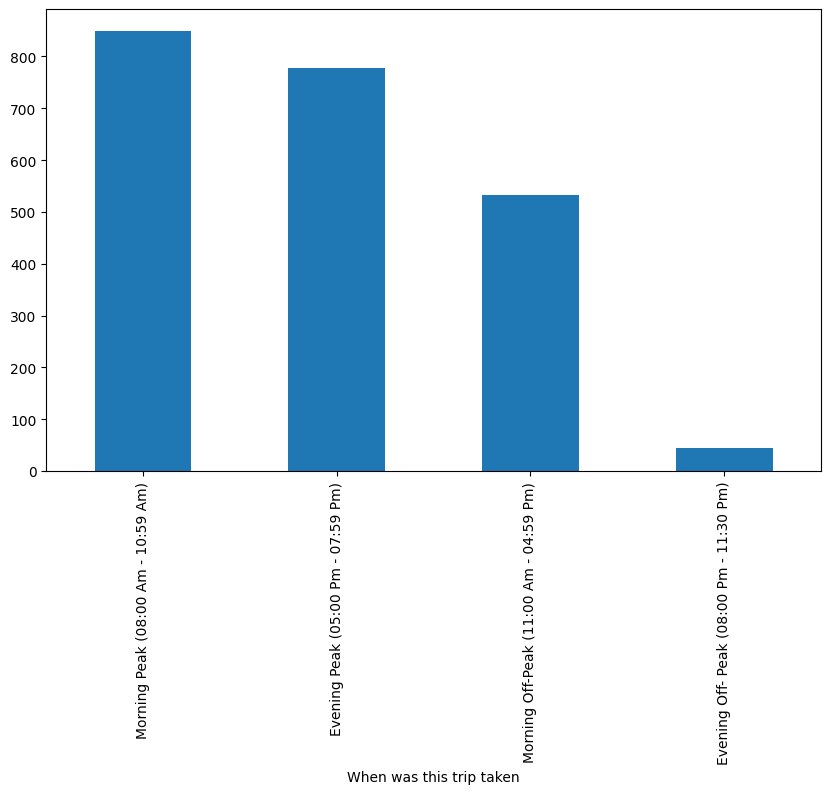

In [200]:
# When was this trip taken
column_name_when_was_trip_taken = 'When was this trip taken'
# Null values in when was trip taken
null_values_when_was_trip_taken = d[column_name_when_was_trip_taken].isnull().sum()
print(f"Number of null values in 'When was this trip taken': {null_values_when_was_trip_taken}")

# unique values when was trip taken
print(d[column_name_when_was_trip_taken].unique())
# value counts when was trip taken
print(d[column_name_when_was_trip_taken].value_counts())
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_when_was_trip_taken].value_counts().plot(kind='bar')

Number of null values in 'When do you make the return': 0
['Morning Peak (08:00 Am - 10:59 Am)'
 'Evening Off- Peak (08:00 Pm - 11:30 Pm)'
 'Early Morning (06:00 Am - 07:59 Am)'
 'Morning Off-Peak (11:00 Am - 04:59 Pm)'
 'Evening Peak (05:00 Pm - 07:59 Pm)']
When do you make the return 
Evening Peak (05:00 Pm - 07:59 Pm)         798
Morning Peak (08:00 Am - 10:59 Am)         614
Evening Off- Peak (08:00 Pm - 11:30 Pm)    447
Early Morning (06:00 Am - 07:59 Am)        220
Morning Off-Peak (11:00 Am - 04:59 Pm)     126
Name: count, dtype: int64


<Axes: xlabel='When do you make the return '>

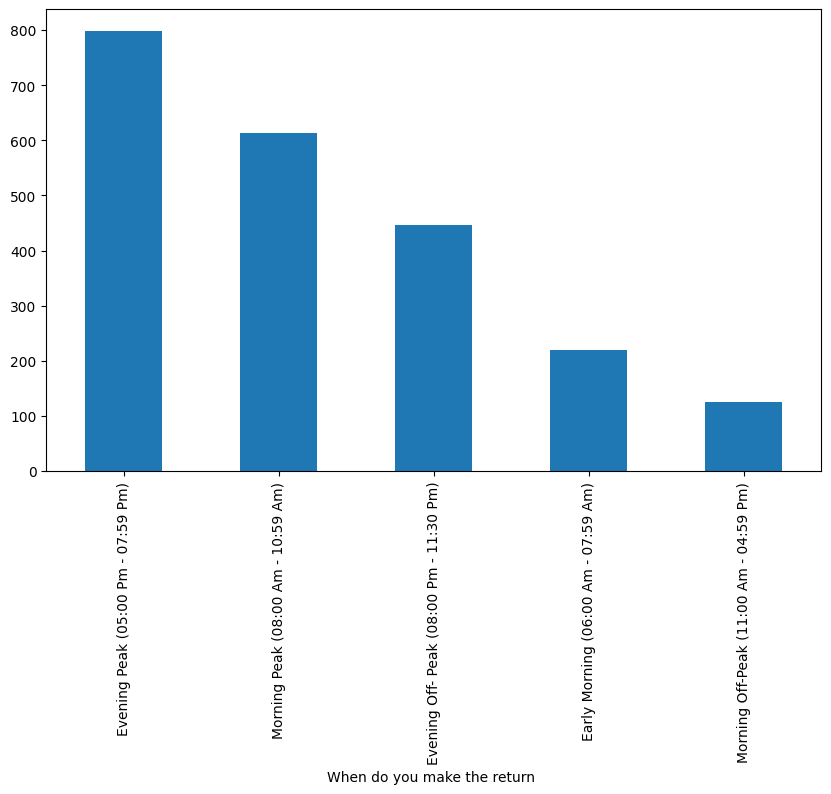

In [201]:
# When do you make the return 
column_name_when_do_you_make_return = 'When do you make the return '
# Null values in when do you make return
null_values_when_do_you_make_return = d[column_name_when_do_you_make_return].isnull().sum()
print(f"Number of null values in 'When do you make the return': {null_values_when_do_you_make_return}")

# unique values when do you make return
print(d[column_name_when_do_you_make_return].unique())
# value counts when do you make return
print(d[column_name_when_do_you_make_return].value_counts())
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_when_do_you_make_return].value_counts().plot(kind='bar')

Number of null values in 'First mile connection (Leg 1)': 0
Unique values in 'First mile connection (Leg 1)': ['Walk' 'Somebody Picks Or Drops Me (Including Carpool)' 'Auto (Shared)'
 'Two-Wheeler (Self-Drive)' 'Cycle' 'Auto (Hail-Regular)'
 'Auto (App Based- Ola/ Uber/ Rapido)'
 'Public Bicycle Sharing (App Based- Yulu)'
 'Two-Wheeler (App Based- Rapido)' 'Four-Wheeler (Self-Drive)'
 'Taxi (App Based)']
First mile connection (Leg 1)
Walk           1629
Auto            298
Two-wheeler     188
Others           43
Car/Taxi         25
Cycle            22
Name: count, dtype: int64


<Axes: xlabel='First mile connection (Leg 1)'>

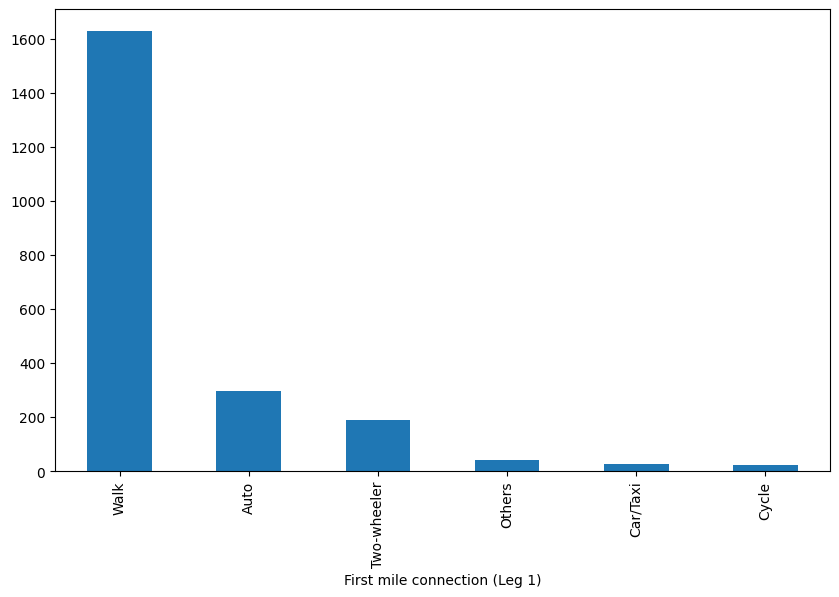

In [202]:
#First mile connection (Leg 1)

column_name_first_mile_leg_1 = 'First mile connection (Leg 1)'
# Null values in first mile leg 1
null_values = d[column_name_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'First mile connection (Leg 1)': {null_values}")

# Unique values in first mile leg 1
unique_values_leg_1 = d[column_name_first_mile_leg_1].unique()
print(f"Unique values in 'First mile connection (Leg 1)': {unique_values_leg_1}")

mapping = {
    'Auto': 'Auto',
    'Auto (Shared)': 'Auto',
    'Two-Wheeler (Self-Drive)': 'Two-wheeler',
    'Somebody Picks Or Drops Me (Including Carpool)': 'Others',
    'Cycle': 'Cycle',
    'Auto (Hail-Regular)': 'Auto',
    'Auto (App Based- Ola/ Uber/ Rapido)': 'Auto',
    'Public Bicycle Sharing (App Based- Yulu)': 'Cycle',
    'Two-Wheeler (App Based- Rapido)': 'Two-wheeler',
    'Four-Wheeler (Self-Drive)': 'Car/Taxi',
    'Taxi (App Based)': 'Car/Taxi',
    'Walk': 'Walk',
}

d[column_name_first_mile_leg_1] = d[column_name_first_mile_leg_1].replace(mapping)

# Value counts in first mile leg 1
value_counts = d[column_name_first_mile_leg_1].value_counts()
print(value_counts)

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_first_mile_leg_1].value_counts().plot(kind='bar')

Number of null values in 'First mile connection (Leg 2)': 1994
Number of null values in 'First mile connection (Leg 2)' after filling: 0
['No First mile leg 2' 'Walk' 'Auto' 'Cycle' 'Others' 'Two-wheeler'
 'Car/Taxi']
First mile connection (Leg 2)
No First mile leg 2    1994
Auto                     94
Two-wheeler              50
Walk                     31
Cycle                    19
Others                    9
Car/Taxi                  8
Name: count, dtype: int64


C:\Users\maddi\AppData\Local\Temp\ipykernel_13664\2608440453.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d[column_name_First_mile_leg_2].fillna("No First mile leg 2", inplace=True)


<Axes: xlabel='First mile connection (Leg 2)'>

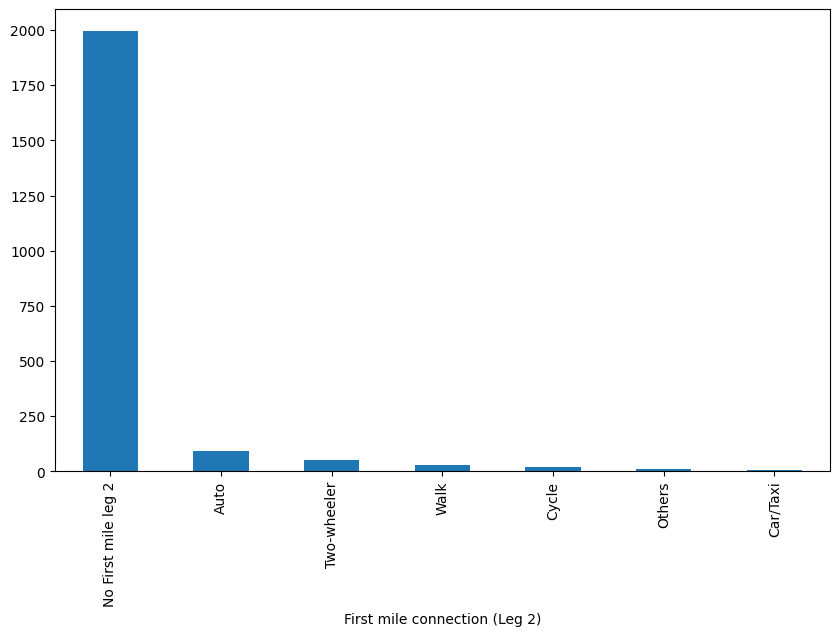

In [203]:
# First mile connection (Leg 2)

column_name_First_mile_leg_2 = 'First mile connection (Leg 2)'

# Null values in first mile leg 2
null_values_leg_2 = d[column_name_First_mile_leg_2].isnull().sum()
print(f"Number of null values in 'First mile connection (Leg 2)': {null_values_leg_2}")

# Fill Null values
d[column_name_First_mile_leg_2].fillna("No First mile leg 2", inplace=True)

null_values_leg_2_after = d[column_name_First_mile_leg_2].isnull().sum()
print(f"Number of null values in 'First mile connection (Leg 2)' after filling: {null_values_leg_2_after}")

mapping = {
    'Auto': 'Auto',
    'Auto (Shared)': 'Auto',
    'Two-Wheeler (Self-Drive)': 'Two-wheeler',
    'Somebody Picks Or Drops Me (Including Carpool)': 'Others',
    'Cycle': 'Cycle',
    'Auto (Hail-Regular)': 'Auto',
    'Auto (App Based- Ola/ Uber/ Rapido)': 'Auto',
    'Public Bicycle Sharing (App Based- Yulu)': 'Cycle',
    'Two-Wheeler (App Based- Rapido)': 'Two-wheeler',
    'Four-Wheeler (Self-Drive)': 'Car/Taxi',
    'Taxi (App Based)': 'Car/Taxi',
    'Walk': 'Walk',
    'No First mile leg 2': 'No First mile leg 2',
}
d[column_name_First_mile_leg_2] = d[column_name_First_mile_leg_2].replace(mapping)
print(d[column_name_First_mile_leg_2].unique())

# Value counts in first mile leg 2
value_counts_leg_2 = d[column_name_First_mile_leg_2].value_counts()
print(value_counts_leg_2)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_First_mile_leg_2].value_counts().plot(kind='bar')

Number of null values in 'Primary Mode (Leg 1)': 0
['Any Others, Please Specify' 'Bmtc Bus' 'Company Transport' 'Kstrc Bus'
 'Metro' 'Train']
Primary Mode (Leg 1)
Metro     2155
Bus         44
Train        4
Others       2
Name: count, dtype: int64


<Axes: xlabel='Primary Mode (Leg 1)'>

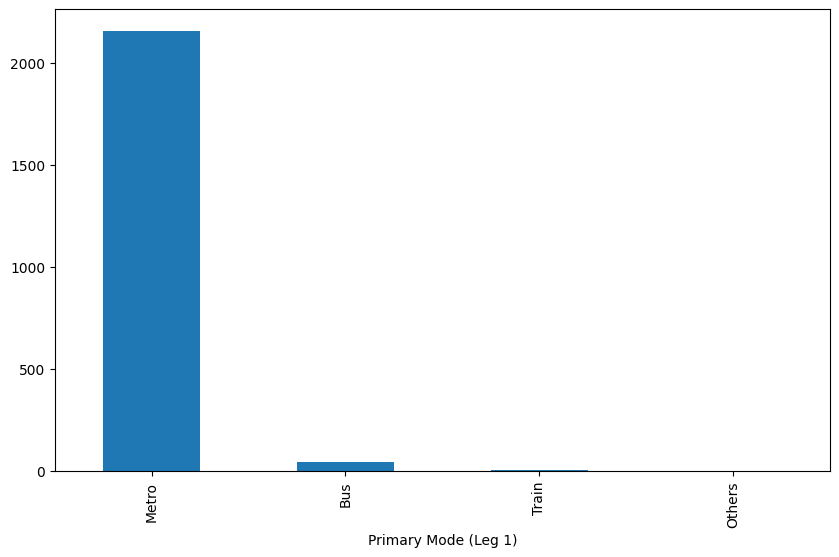

In [204]:
# Primary Mode (Leg 1)

column_name_primary_mode_leg_1 = 'Primary Mode (Leg 1)'

# Null values in primary mode
null_values_primary_mode = d[column_name_primary_mode_leg_1].isnull().sum()
print(f"Number of null values in 'Primary Mode (Leg 1)': {null_values_primary_mode}")

# Unique values in primary mode
print(d[column_name_primary_mode_leg_1].unique())

mapping = {
    'Metro' : 'Metro',
    'Bmtc Bus' : 'Bus',
    'Kstrc Bus' : 'Bus',
    'Train' : 'Train',
    'Any Others, Please Specify' : 'Others',
    'Company Transport' : 'Others'
}
d[column_name_primary_mode_leg_1] = d[column_name_primary_mode_leg_1].replace(mapping)

# Value counts in primary mode
value_counts_primary_mode = d[column_name_primary_mode_leg_1].value_counts()
print(value_counts_primary_mode)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_primary_mode_leg_1].value_counts().plot(kind='bar')

Number of null values in 'Primary Mode (Leg 2)': 1913
['Metro' 'Bmtc Bus' 'Company Transport' 'Kstrc Bus' 'Metro Feeder Bus'
 'No Primary mode leg 2' 'Train']
Primary Mode (Leg 2)
No Primary mode leg 2    1913
Bus                       236
Metro                      50
Others                      3
Train                       3
Name: count, dtype: int64


C:\Users\maddi\AppData\Local\Temp\ipykernel_13664\3198835453.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d[column_name_primary_mode_leg_2].fillna("No Primary mode leg 2", inplace=True)


<Axes: xlabel='Primary Mode (Leg 2)'>

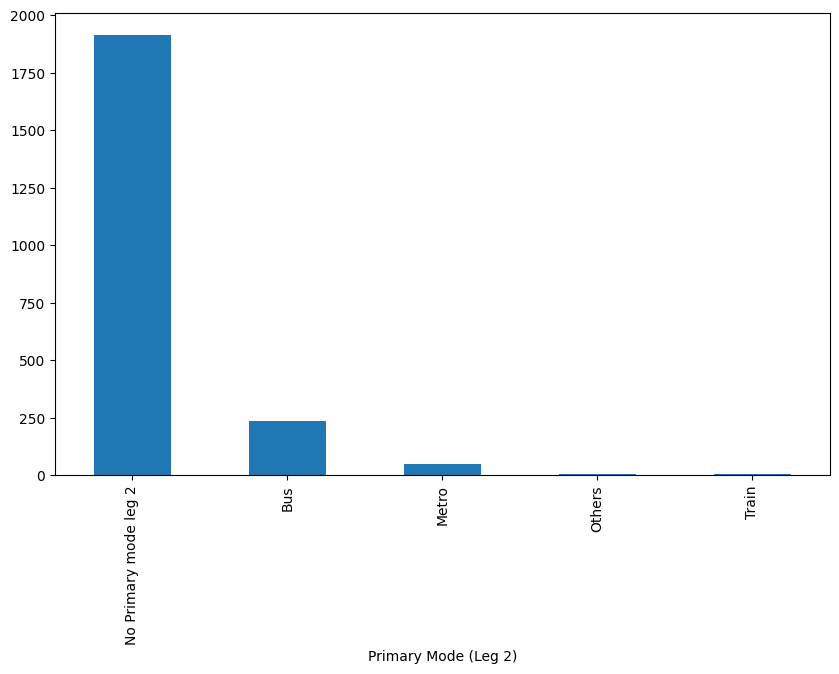

In [205]:
# Primary Mode (Leg 2)
column_name_primary_mode_leg_2 = 'Primary Mode (Leg 2)'

# Null values in primary mode leg 2
null_values_primary_mode_leg_2 = d[column_name_primary_mode_leg_2].isnull().sum()
print(f"Number of null values in 'Primary Mode (Leg 2)': {null_values_primary_mode_leg_2}")


# Replace null values with "No Primary mode leg 2"
d[column_name_primary_mode_leg_2].fillna("No Primary mode leg 2", inplace=True)

# Unique values in primary mode leg 2
print(d[column_name_primary_mode_leg_2].unique())

mapping = {
    'No Primary mode leg 2' : 'No Primary mode leg 2',
    'Metro' : 'Metro',
    'Bmtc Bus' : 'Bus',
    'Kstrc Bus' : 'Bus',
    'Train' : 'Train',
    'Metro Feeder Bus' : 'Others',
    'Company Transport' : 'Others'
}
d[column_name_primary_mode_leg_2] = d[column_name_primary_mode_leg_2].replace(mapping)

# Value counts in primary mode leg 2
value_counts_primary_mode_leg_2 = d[column_name_primary_mode_leg_2].value_counts()
print(value_counts_primary_mode_leg_2)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_primary_mode_leg_2].value_counts().plot(kind='bar')

Number of null values in 'Last Mile connection (Leg 1)': 0
['Walk' 'Auto (App Based- Ola/ Uber/ Rapido)' 'Auto (Hail-Regular)'
 'Auto (Shared)' 'Somebody Picks Or Drops Me (Including Carpool)'
 'Two-Wheeler (App Based- Rapido)' 'Cycle'
 'Public Bicycle Sharing (App Based- Yulu)' 'Taxi (App Based)'
 'Two-Wheeler (Self-Drive)']
Last Mile connection (Leg 1)
Walk           1827
Auto            272
Others           34
Two-wheeler      26
Car/Taxi         24
Cycle            22
Name: count, dtype: int64


<Axes: xlabel='Last Mile connection (Leg 1)'>

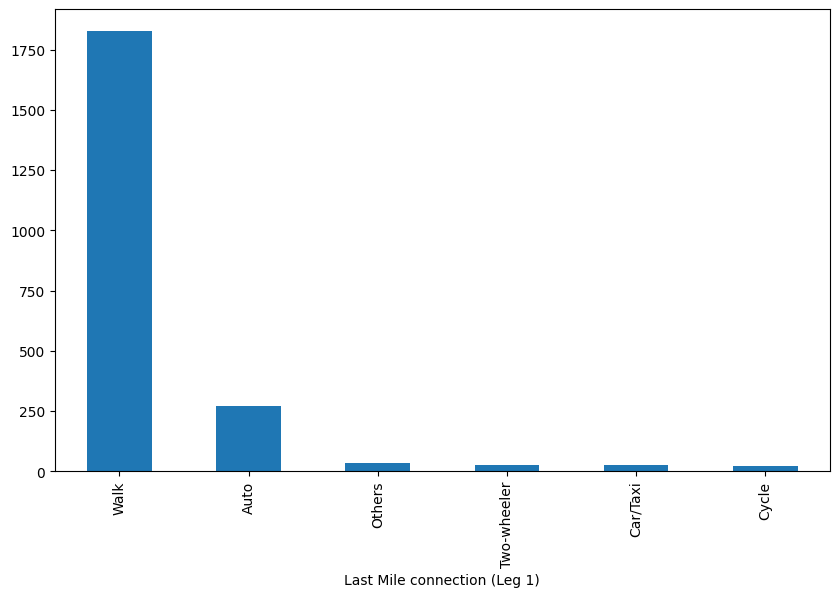

In [206]:
# Last Mile connection (Leg 1)
column_name_last_mile_leg_1 = 'Last Mile connection (Leg 1)'
# Null values in last mile leg 1
null_values_last_mile_leg_1 = d[column_name_last_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Last Mile connection (Leg 1)': {null_values_last_mile_leg_1}")

# Unique values in last mile leg 1
print(d[column_name_last_mile_leg_1].unique())

mapping = {
    'Auto': 'Auto',
    'Auto (Shared)': 'Auto',
    'Two-Wheeler (Self-Drive)': 'Two-wheeler',
    'Somebody Picks Or Drops Me (Including Carpool)': 'Others',
    'Cycle': 'Cycle',
    'Auto (Hail-Regular)': 'Auto',
    'Auto (App Based- Ola/ Uber/ Rapido)': 'Auto',
    'Public Bicycle Sharing (App Based- Yulu)': 'Cycle',
    'Two-Wheeler (App Based- Rapido)': 'Two-wheeler',
    'Four-Wheeler (Self-Drive)': 'Car/Taxi',
    'Taxi (App Based)': 'Car/Taxi',
    'Walk': 'Walk',
}

d[column_name_last_mile_leg_1] = d[column_name_last_mile_leg_1].replace(mapping)

# Value counts in last mile leg 1
value_counts_last_mile_leg_1 = d[column_name_last_mile_leg_1].value_counts()
print(value_counts_last_mile_leg_1)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_last_mile_leg_1].value_counts().plot(kind='bar')

Number of null values in 'Last Mile connection (Leg 2)': 2135
['No Last mile leg 2' 'Auto (Shared)' 'Walk'
 'Auto (App Based- Ola/ Uber/ Rapido)' 'Cycle' 'Four-Wheeler (Self-Drive)'
 'Public Bicycle Sharing (App Based- Yulu)'
 'Somebody Picks Or Drops Me (Including Carpool)' 'Auto (Hail-Regular)'
 'Two-Wheeler (App Based- Rapido)' 'Two-Wheeler (Self-Drive)']
Last Mile connection (Leg 2)
No Last mile leg 2    2135
Walk                    41
Auto                    15
Cycle                    8
Two-wheeler              3
Others                   2
Car/Taxi                 1
Name: count, dtype: int64


C:\Users\maddi\AppData\Local\Temp\ipykernel_13664\2752432732.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d[column_name_last_mile_leg_2].fillna("No Last mile leg 2", inplace=True)


<Axes: xlabel='Last Mile connection (Leg 2)'>

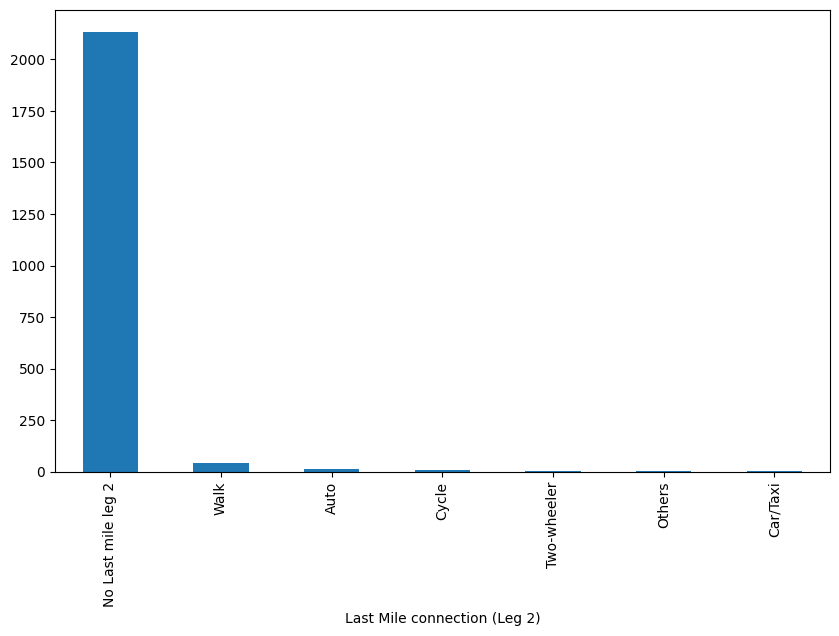

In [207]:
# Last Mile connection (Leg 2)
column_name_last_mile_leg_2 = 'Last Mile connection (Leg 2)'
# Null values in last mile leg 2
null_values_last_mile_leg_2 = d[column_name_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Last Mile connection (Leg 2)': {null_values_last_mile_leg_2}")

# Fill Null values
d[column_name_last_mile_leg_2].fillna("No Last mile leg 2", inplace=True)

# Unique values in last mile leg 2
print(d[column_name_last_mile_leg_2].unique())

mapping = {
    'No Last mile leg 2': 'No Last mile leg 2',
    'Auto': 'Auto',
    'Auto (Shared)': 'Auto',
    'Two-Wheeler (Self-Drive)': 'Two-wheeler',
    'Somebody Picks Or Drops Me (Including Carpool)': 'Others',
    'Cycle': 'Cycle',
    'Auto (Hail-Regular)': 'Auto',
    'Auto (App Based- Ola/ Uber/ Rapido)': 'Auto',
    'Public Bicycle Sharing (App Based- Yulu)': 'Cycle',
    'Two-Wheeler (App Based- Rapido)': 'Two-wheeler',
    'Four-Wheeler (Self-Drive)': 'Car/Taxi',
    'Taxi (App Based)': 'Car/Taxi',
    'Walk': 'Walk',
}

d[column_name_last_mile_leg_2] = d[column_name_last_mile_leg_2].replace(mapping)
# Value counts in last mile leg 2
value_counts_last_mile_leg_2 = d[column_name_last_mile_leg_2].value_counts()
print(value_counts_last_mile_leg_2)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_last_mile_leg_2].value_counts().plot(kind='bar')

Number of null values in 'How do you usually pay for your Metro journey?': 0
Q10. How do you usually pay  for your Metro journey?
Smartcard (Pay As You Like)                      1278
Single Ticket                                     479
Day Pass (1 Day/ 3 Days)                          229
Monthly Pass                                      178
Group Ticket                                       38
Mobile Application (Please Specify Which One)       3
Name: count, dtype: int64


<Axes: xlabel='Q10. How do you usually pay  for your Metro journey?'>

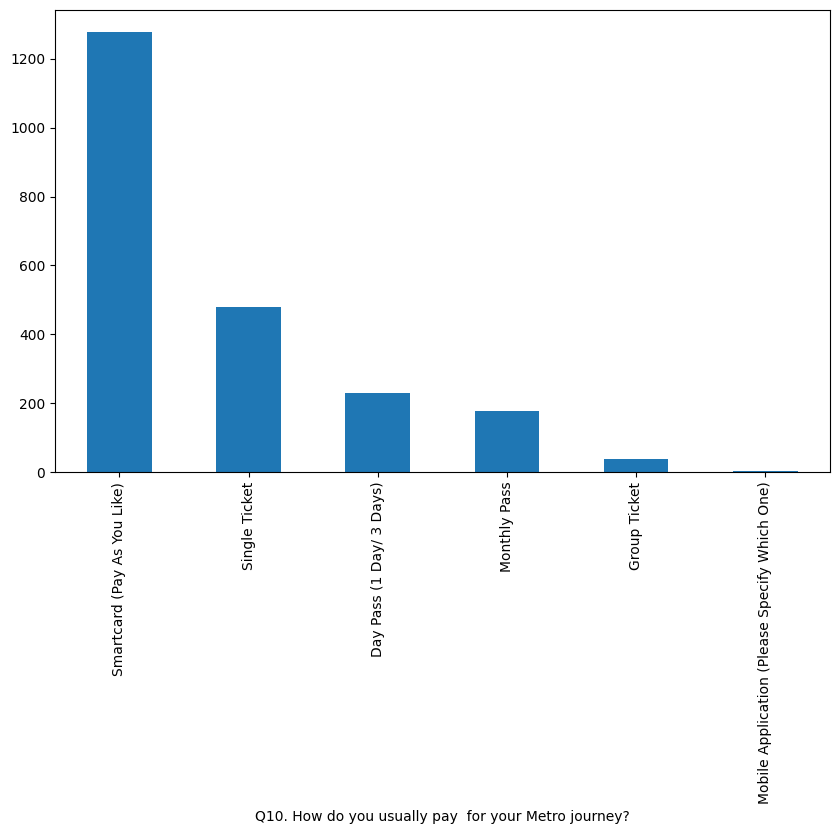

In [208]:
# Q10. How do you usually pay  for your Metro journey?
column_name_payment_method = 'Q10. How do you usually pay  for your Metro journey?'
# Null values in payment method
null_values_payment_method = d[column_name_payment_method].isnull().sum()
print(f"Number of null values in 'How do you usually pay for your Metro journey?': {null_values_payment_method}")

value_counts_payment_method = d[column_name_payment_method].value_counts()
print(value_counts_payment_method)

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_payment_method].value_counts().plot(kind='bar')

Number of null values in 'Gender': 0
Gender
Male      1293
Female     912
Name: count, dtype: int64


<Axes: xlabel='Gender'>

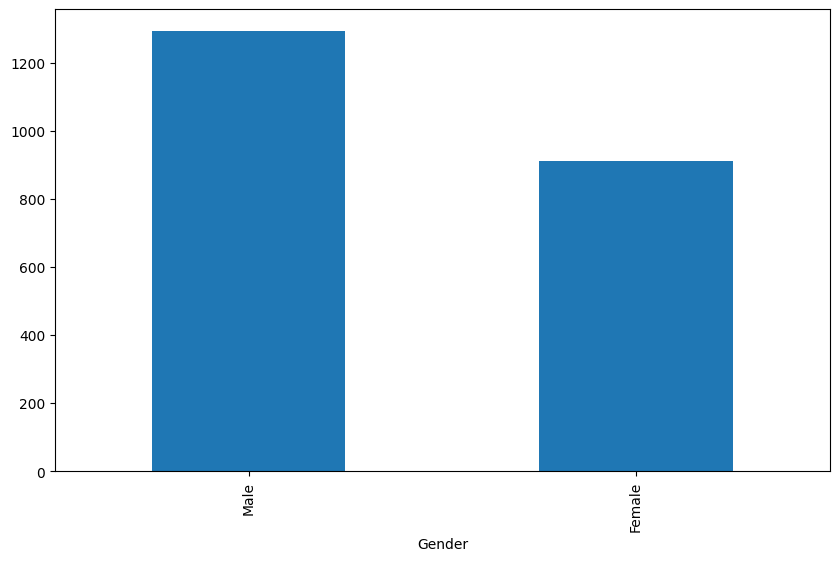

In [209]:
# Gender
column_name_gender = 'Gender'
# Null values in gender
null_values_gender = d[column_name_gender].isnull().sum()
print(f"Number of null values in 'Gender': {null_values_gender}")

# Value counts
value_counts_gender = d[column_name_gender].value_counts()
print(value_counts_gender)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_gender].value_counts().plot(kind='bar')

Number of null values in 'Age': 0
['19 - 25' '26 - 35' '36 - 50' 'Refused' 'Less Than 18' '51-60' '60+']
Age
19 - 25            1043
26 - 35             895
36 - 50             216
Less Than 18         28
Greater than 50      23
Name: count, dtype: int64


<Axes: xlabel='Age'>

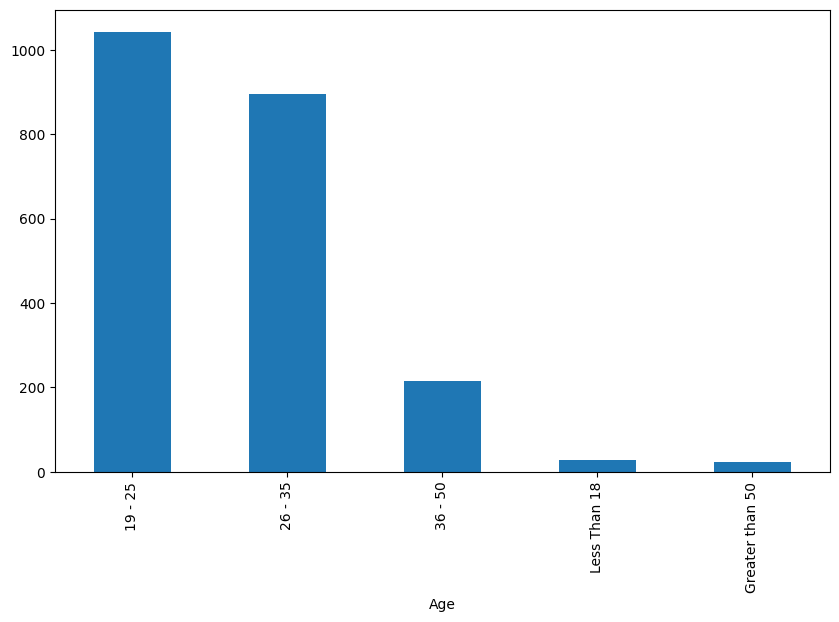

In [210]:
# Age
column_name_age = 'Age'
# Null values in age
null_values_age = d[column_name_age].isnull().sum()
print(f"Number of null values in 'Age': {null_values_age}")
# UNIQUE VALUES
print(d[column_name_age].unique())

mapping = {
    '19 - 25':'19 - 25',
    '26 - 35':'26 - 35',
    '36 - 50':'36 - 50',
    'Refused':'26 - 35',
    'Less Than 18':'Less Than 18',
    '51-60':'Greater than 50',
    '60+':'Greater than 50',
}
d[column_name_age] = d[column_name_age].replace(mapping)

# VALUE COUNTS
value_counts_age = d[column_name_age].value_counts()
print(value_counts_age)

# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_age].value_counts().plot(kind='bar')

Number of null values in 'Educational qualification?': 0
['Bachelors Degree' 'Some College Credit, No Degree' 'Professional Degree'
 'High School Graduate, Diploma, Or The Equivalent (12th Pass)'
 'Trade/Technical/Vocational Training' 'Up To 8th Grade' 'Masters Degree'
 'Doctorate Degree' 'Some High School, No Diploma (10th Pass)'
 'No Schooling Completed']
Educational qualification?
Degree Holder    1198
12th Pass         579
Post Graduate     303
Below 12th        125
Name: count, dtype: int64


<Axes: xlabel='Educational qualification?'>

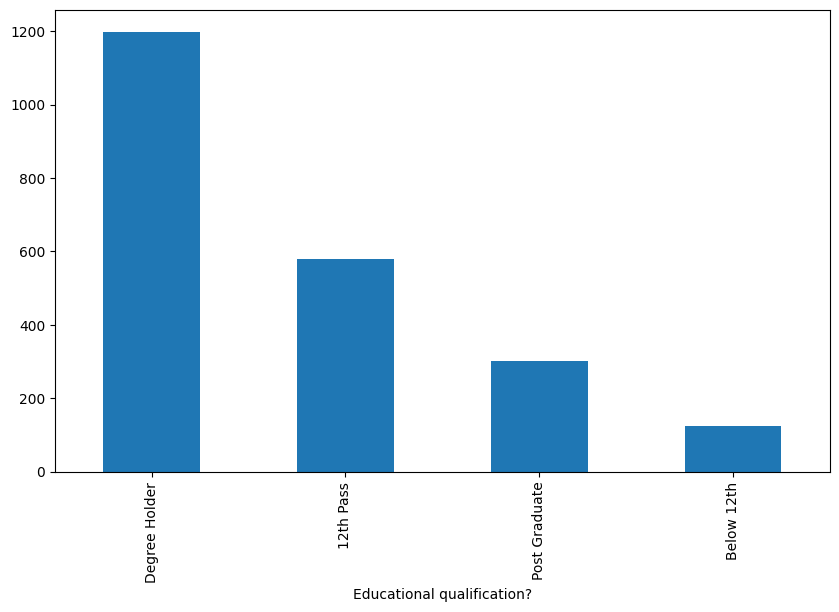

In [211]:
# Educational qualification?
column_name_education = 'Educational qualification?'
# Null values in educational qualification
null_values_education = d[column_name_education].isnull().sum()
print(f"Number of null values in 'Educational qualification?': {null_values_education}")

# UNIQUE VALUES
print(d[column_name_education].unique())

mapping = {
    'Bachelors Degree' : 'Degree Holder',
    'Some College Credit, No Degree' : '12th Pass',
    'Professional Degree' : 'Degree Holder',    
    'High School Graduate, Diploma, Or The Equivalent (12th Pass)' : '12th Pass',
    'Trade/Technical/Vocational Training' : '12th Pass',
    'Up To 8th Grade' : 'Below 12th',
    'Masters Degree' : 'Post Graduate',
    'Doctorate Degree' : 'Post Graduate',
    'Some High School, No Diploma (10th Pass)' : 'Below 12th',
    'No Schooling Completed' : 'Below 12th'
}

d[column_name_education] = d[column_name_education].replace(mapping)

# VALUE COUNTS
value_counts_education = d[column_name_education].value_counts()
print(value_counts_education)

# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_education].value_counts().plot(kind='bar')


Number of null values in 'Occupation': 0
['A Student' 'Employed' 'Self-Employed' 'A Homemaker' 'Awaiting Job'
 'Unemployed' 'Daily Wage Worker' 'Retired' 'Unable To Work']
Occupation
Employed             1525
Student               451
Self-Employed         135
Homemaker              41
Daily Wage Worker      29
Unemployed             20
Retired                 4
Name: count, dtype: int64


<Axes: xlabel='Occupation'>

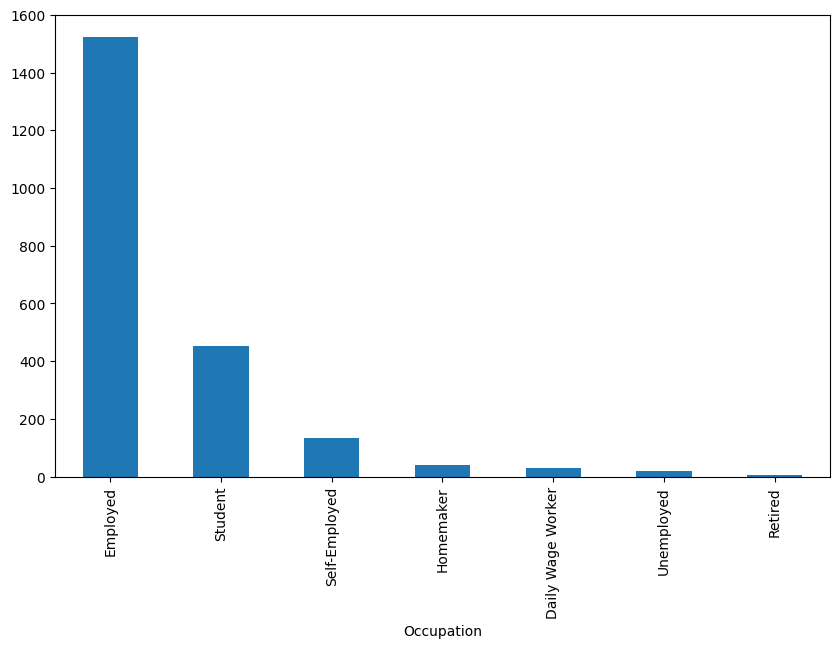

In [212]:
# Occupation

column_name_occupation = 'Occupation'
# Null values in occupation
null_values_occupation = d[column_name_occupation].isnull().sum()
print(f"Number of null values in 'Occupation': {null_values_occupation}")
# UNIQUE VALUES
print(d[column_name_occupation].unique())

mapping = {'A Student' : 'Student', 
           'Employed' : 'Employed', 
           'Self-Employed' : 'Self-Employed', 
           'A Homemaker' : 'Homemaker',
             'Awaiting Job' : 'Unemployed',
           'Unemployed' : 'Unemployed', 
           'Daily Wage Worker' : 'Daily Wage Worker', 
           'Retired' : 'Retired', 
           'Unable To Work' : 'Unemployed'}
d[column_name_occupation] = d[column_name_occupation].replace(mapping)

# VALUE COUNTS
value_counts_occupation = d[column_name_occupation].value_counts()
print(value_counts_occupation)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_occupation].value_counts().plot(kind='bar')

Number of null values in 'Monthly household income': 0
count              2205
unique                9
top       20,001-40,000
freq                766
Name: Monthly household income, dtype: object
['5,001 -10,000' '20,001-40,000' '40,001-60,000' '60,001-80,000'
 'Above 1,00,000' 'Refused' '80,001 - 1,00,000' '10,001-20,000' '<5k']
Monthly household income
20,001-40,000    930
10,001-20,000    434
40,001-60,000    402
Above 60,000     220
5,001-10,000     150
<5k               69
Name: count, dtype: int64


<Axes: xlabel='Monthly household income'>

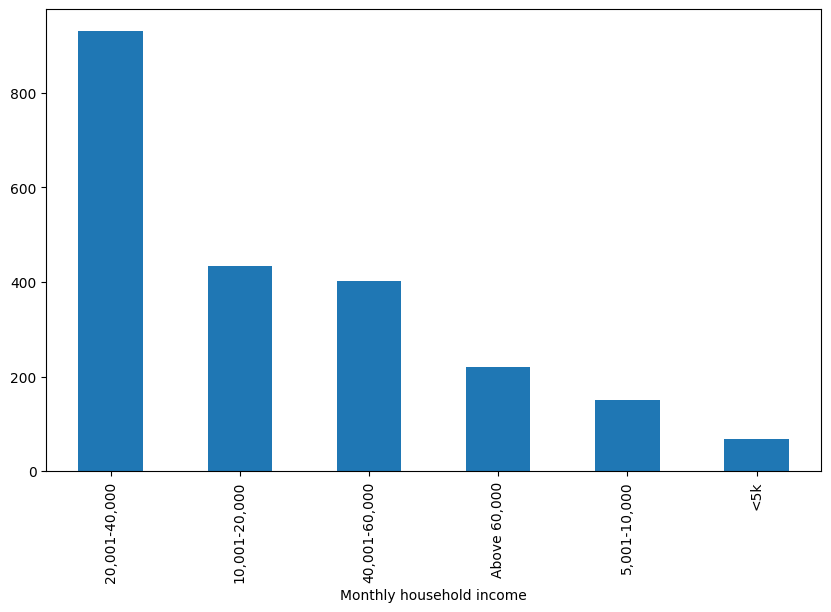

In [213]:
# Monthly household income
column_name_monthly_income = 'Monthly household income'
# Null values in monthly household income
null_values_monthly_income = d[column_name_monthly_income].isnull().sum()
print(f"Number of null values in 'Monthly household income': {null_values_monthly_income}")

print(d[column_name_monthly_income].describe())
# UNIQUE VALUES
print(d[column_name_monthly_income].unique())

mapping = {
    '5,001 -10,000': '5,001-10,000',
    '10,001-20,000': '10,001-20,000',
    '20,001-40,000': '20,001-40,000',
    '40,001-60,000': '40,001-60,000',
    '60,001-80,000': 'Above 60,000',
    '80,001 - 1,00,000': 'Above 60,000',
    'Above 1,00,000': 'Above 60,000',
    'Refused': '20,001-40,000',
    '<5k': '<5k'
}

d[column_name_monthly_income] = d[column_name_monthly_income].replace(mapping)

# VALUE COUNTS
value_counts_monthly_income = d[column_name_monthly_income].value_counts()
print(value_counts_monthly_income)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_monthly_income].value_counts().plot(kind='bar')



In [214]:
# Household members

column_name_household_members = 'Household members'
# Null values in household members
null_values_household_members = d[column_name_household_members].isnull().sum()
print(f"Number of null values in 'Household members': {null_values_household_members}")

unique_values_household_members = d[column_name_household_members].unique()
print(f"Unique values in 'Household members': {unique_values_household_members}")



Number of null values in 'Household members': 0
Unique values in 'Household members': [ 4  3  5  7  6  1 12  8  2 10 13  9 15]


Number of null values in 'Number of vehicles in the household - 2W:': 0
[ 2  1  3  0 10 11  5  4]
Number of vehicles in the household - 2W:
One                 1339
Two                  462
Zero                 342
3                     54
Greater than Two       8
Name: count, dtype: int64


<Axes: xlabel='Number of vehicles in the household - 2W:'>

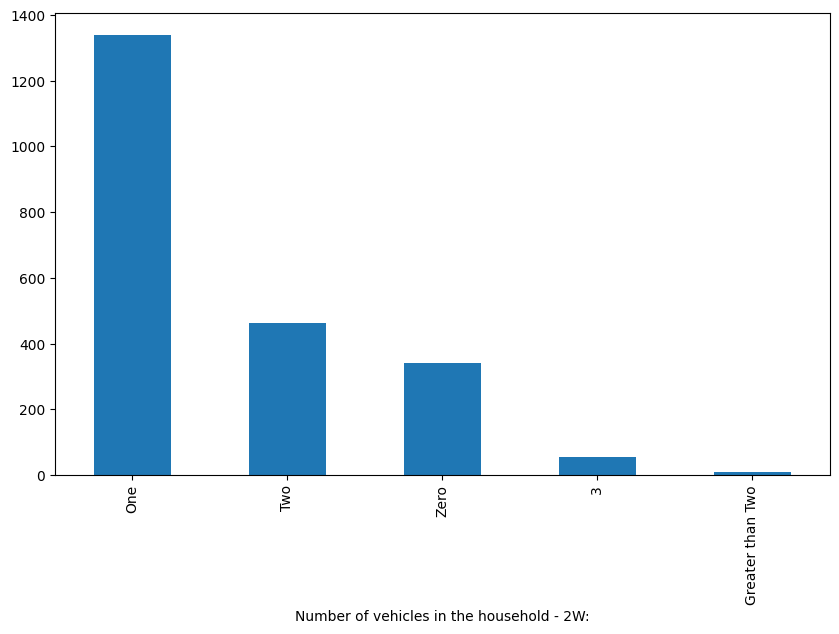

In [215]:
# Number of vehicles in the household - 2W:
column_name_vehicles_2w = 'Number of vehicles in the household - 2W:'
# Null values in 2W vehicles
null_values_vehicles_2w = d[column_name_vehicles_2w].isnull().sum()
print(f"Number of null values in 'Number of vehicles in the household - 2W:': {null_values_vehicles_2w}")

print(d[column_name_vehicles_2w].unique())

mapping = {
    0 : 'Zero'
    , 1 : 'One'
    , 2 : 'Two'
    , 10 : 'Greater than Two'
    , 5 : 'Greater than Two'
    , 11 : 'Greater than Two'
    , 4 : 'Greater than Two'
}
d[column_name_vehicles_2w] = d[column_name_vehicles_2w].replace(mapping)


value_counts_vehicles_2w = d[column_name_vehicles_2w].value_counts()
print(value_counts_vehicles_2w)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_vehicles_2w].value_counts().plot(kind='bar')



Number of null values in 'Number of vehicles in the household - 4W': 0
[1 0 2 8 3 4 6]
Number of vehicles in the household - 4W
Zero                1140
One                  940
Two                  118
Greater than Two       7
Name: count, dtype: int64


<Axes: xlabel='Number of vehicles in the household - 4W'>

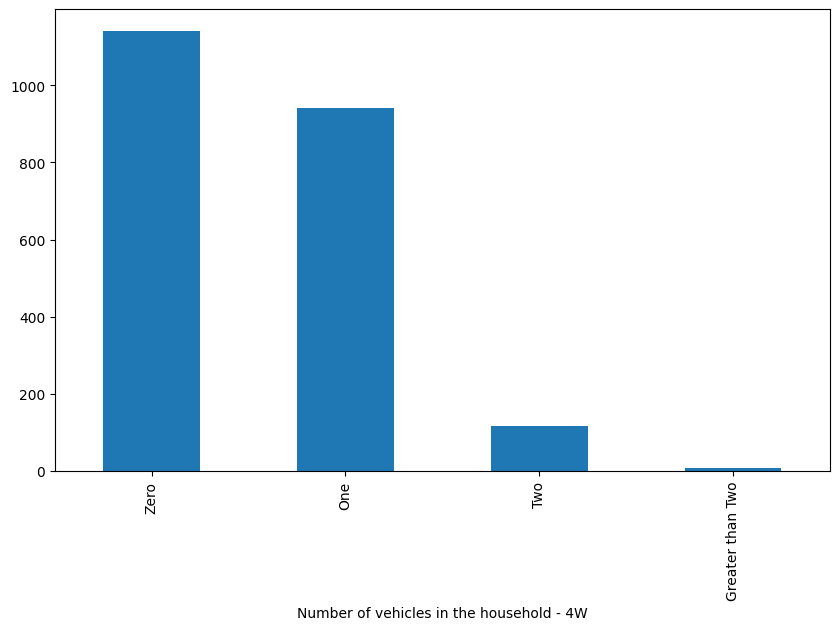

In [216]:
# Number of vehicles in the household - 4W
column_name_vehicles_4w = 'Number of vehicles in the household - 4W'
# Null values in 4W vehicles
null_values_vehicles_4w = d[column_name_vehicles_4w].isnull().sum()
print(f"Number of null values in 'Number of vehicles in the household - 4W': {null_values_vehicles_4w}")
print(d[column_name_vehicles_4w].unique())

mapping = {
    0 : 'Zero'
    , 1 : 'One'
    , 2 : 'Two'
    , 8 : 'Greater than Two'
    , 3 : 'Greater than Two'
    , 4 : 'Greater than Two'
    , 6 : 'Greater than Two'
}

d[column_name_vehicles_4w] = d[column_name_vehicles_4w].replace(mapping)

# VALUE COUNTS
value_counts_vehicles_4w = d[column_name_vehicles_4w].value_counts()
print(value_counts_vehicles_4w)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_vehicles_4w].value_counts().plot(kind='bar')



Number of null values in 'Number of vehicles in the household - Cycle': 0
Number of vehicles in the household - Cycle
Zero                  1379
One                    728
Two                     68
Three                   19
Greater than Three      11
Name: count, dtype: int64


<Axes: xlabel='Number of vehicles in the household - Cycle'>

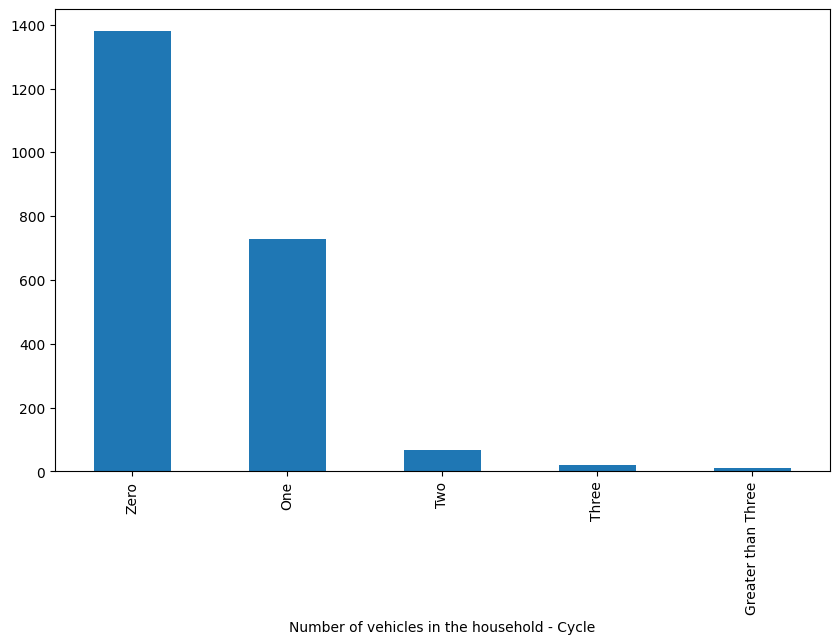

In [217]:
# Number of vehicles in the household - Cycle
column_name_vehicles_cycle = 'Number of vehicles in the household - Cycle'
# Null values in cycle vehicles
null_values_vehicles_cycle = d[column_name_vehicles_cycle].isnull().sum()
print(f"Number of null values in 'Number of vehicles in the household - Cycle': {null_values_vehicles_cycle}")

mapping = {
    0 : 'Zero'
    , 1 : 'One'
    , 2 : 'Two'
    , 3 : 'Three'
    , 8 : 'Greater than Three'
    , 4 : 'Greater than Three'
    , 31 : 'Greater than Three'
    , 5 : 'Greater than Three'
    , 6 : 'Greater than Three'
}

d[column_name_vehicles_cycle] = d[column_name_vehicles_cycle].replace(mapping)

value_counts_vehicles_cycle = d[column_name_vehicles_cycle].value_counts()
print(value_counts_vehicles_cycle)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_vehicles_cycle].value_counts().plot(kind='bar')




In [218]:
# Is there a vehicle belonging to you/your family that you could have used to make this trip?

column_name_vehicle_used = 'Is there a vehicle belonging to you/your family that you could have used to make this trip?'
# Null values in vehicle used
null_values_vehicle_used = d[column_name_vehicle_used].isnull().sum()
print(f"Number of null values in 'Is there a vehicle belonging to you/your family that you could have used to make this trip?': {null_values_vehicle_used}")

value_counts_vehicle_used = d[column_name_vehicle_used].value_counts()
print(value_counts_vehicle_used)

Number of null values in 'Is there a vehicle belonging to you/your family that you could have used to make this trip?': 0
Is there a vehicle belonging to you/your family that you could have used to make this trip?
Yes    1334
No      871
Name: count, dtype: int64


Q7L10. Could you please tell me what is the secondary travel reason to choose by XXXXXX (Last Mile leg 1) and XXXXXX (Last Mile leg 2)?
Most Comfortable Mode                                        431
Safest Mode                                                  424
Most Convenient Mode                                         378
Quickest Mode                                                372
My Trip Is Too Short To Take Any Other Mode                  235
Most Reliable Mode (I Know I Will Get One When I Need To)    207
Most Affordable Mode                                         158
Name: count, dtype: int64
Q7F10. Could you please tell me what is the secondary reason to choose your travel by XXXXXX (First Mile leg 1) and XXXXXX (First Mile leg 2)?
Safest Mode                                                  458
Most Comfortable Mode                                        446
Quickest Mode                                                385
Most Convenient Mode                         

<Axes: xlabel='Q7F9. Could you please tell me what is the primary reason to choose your travel by XXXXXX (First Mile Leg 1) and XXXXXX (First Mile Leg 2)?'>

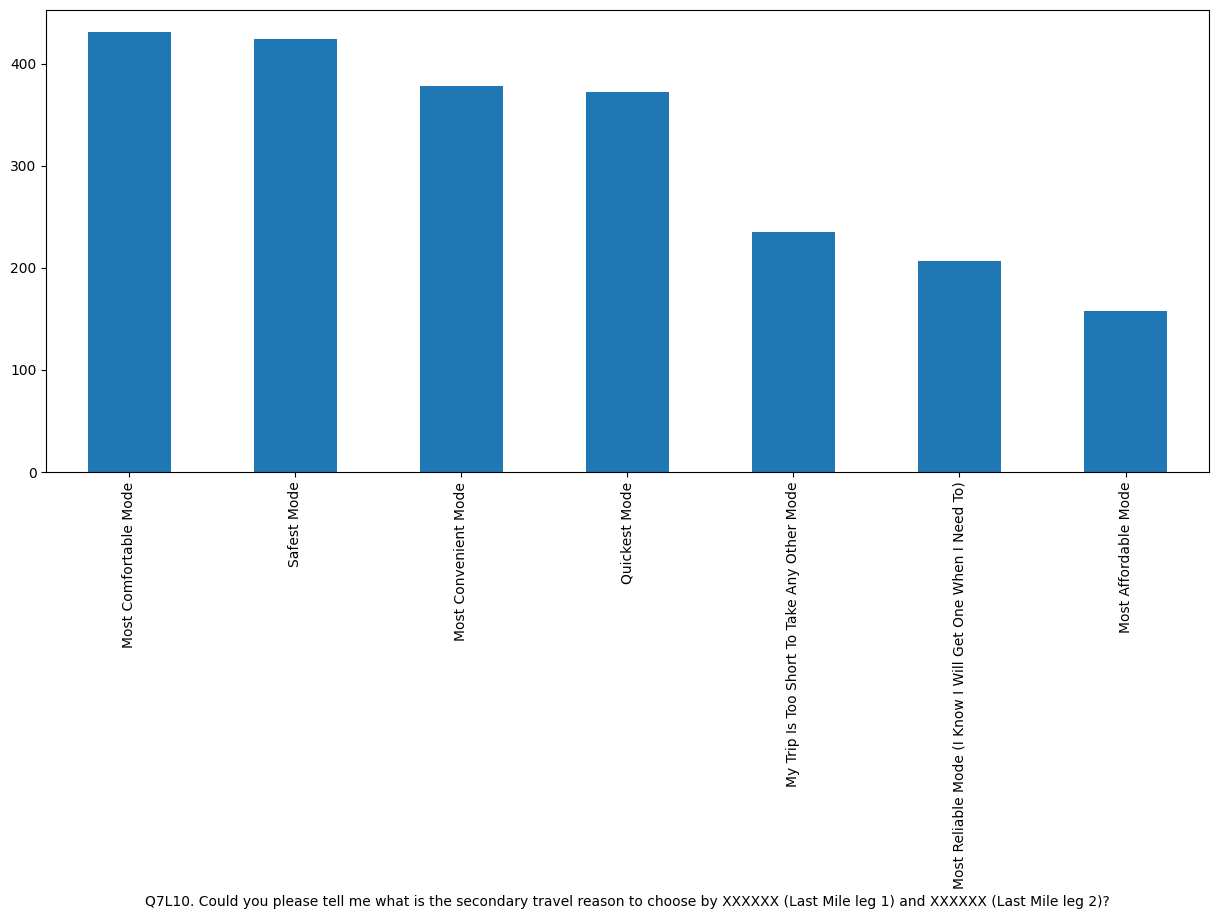

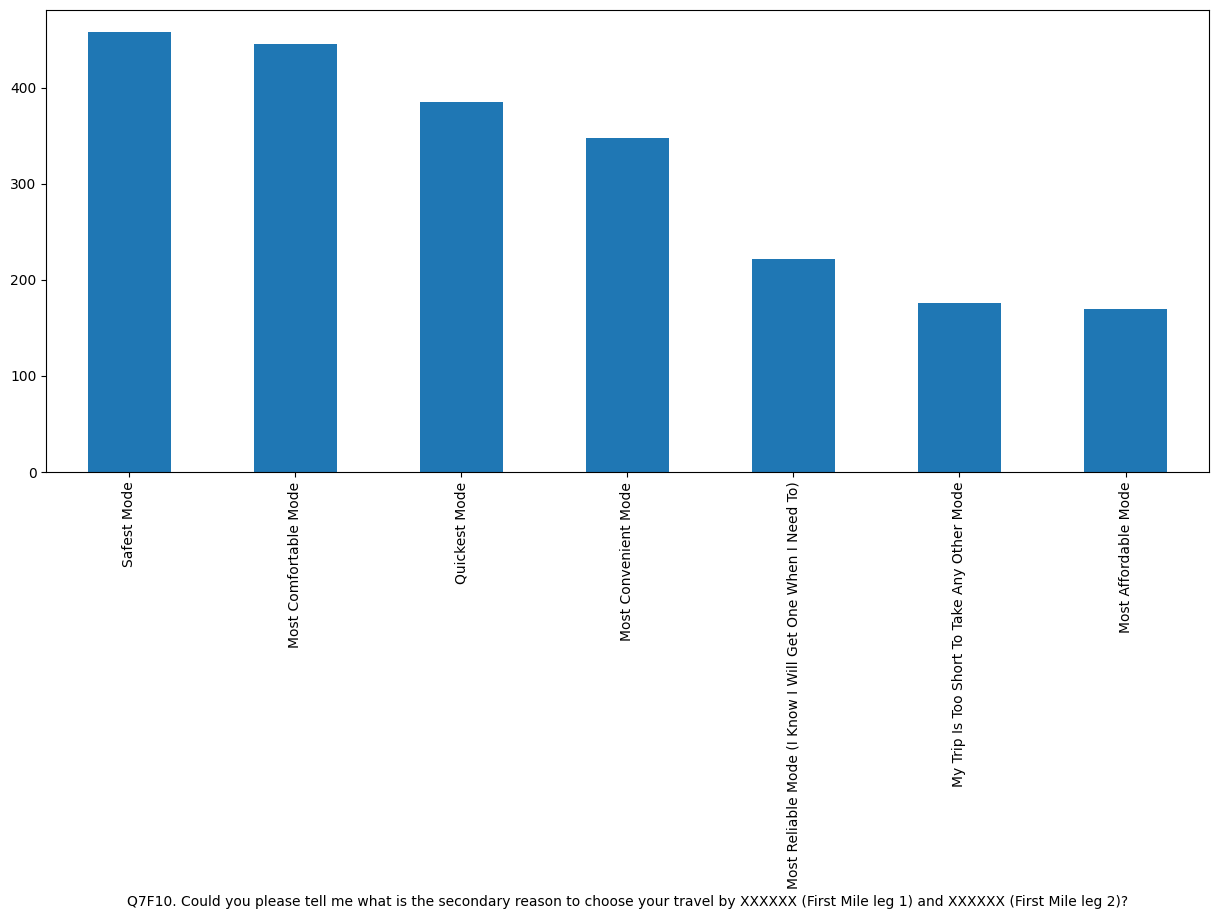

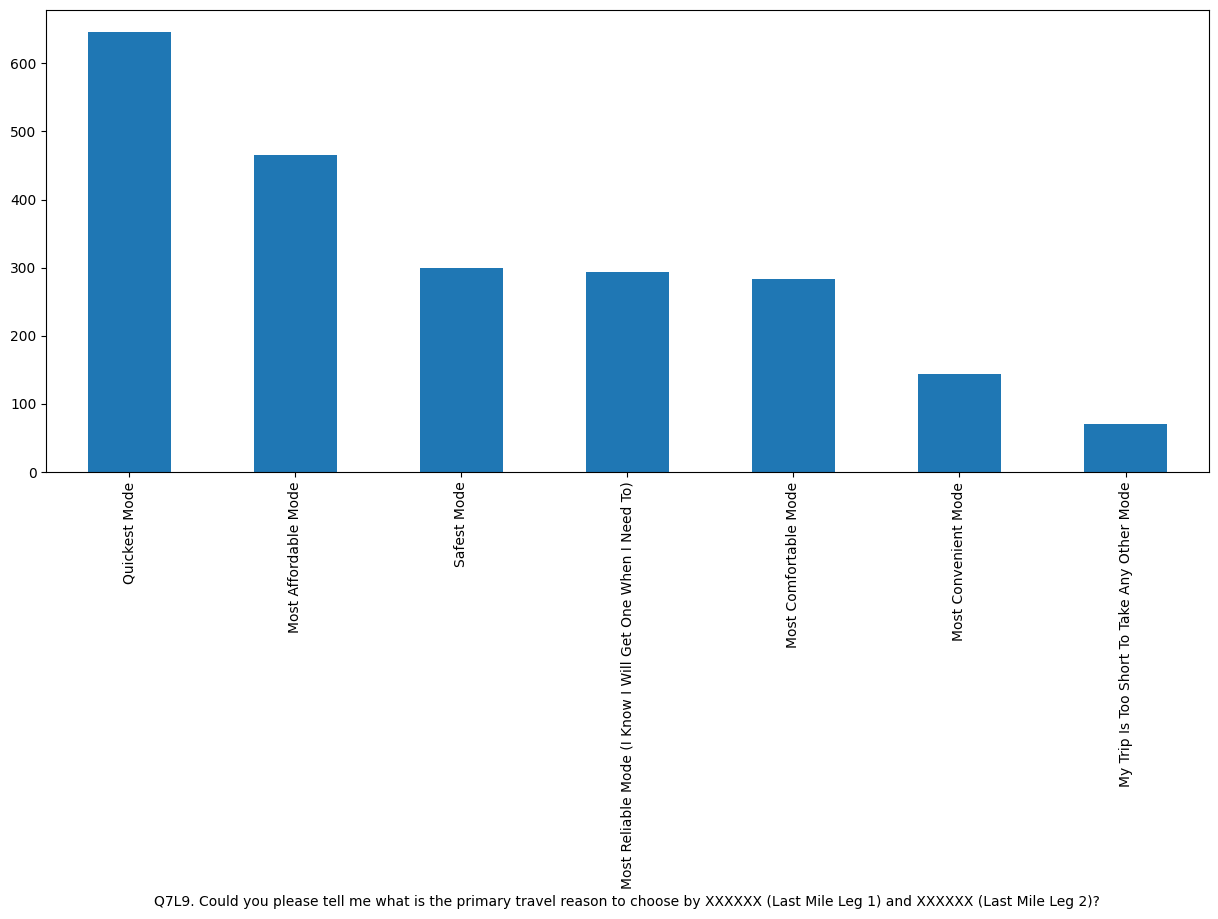

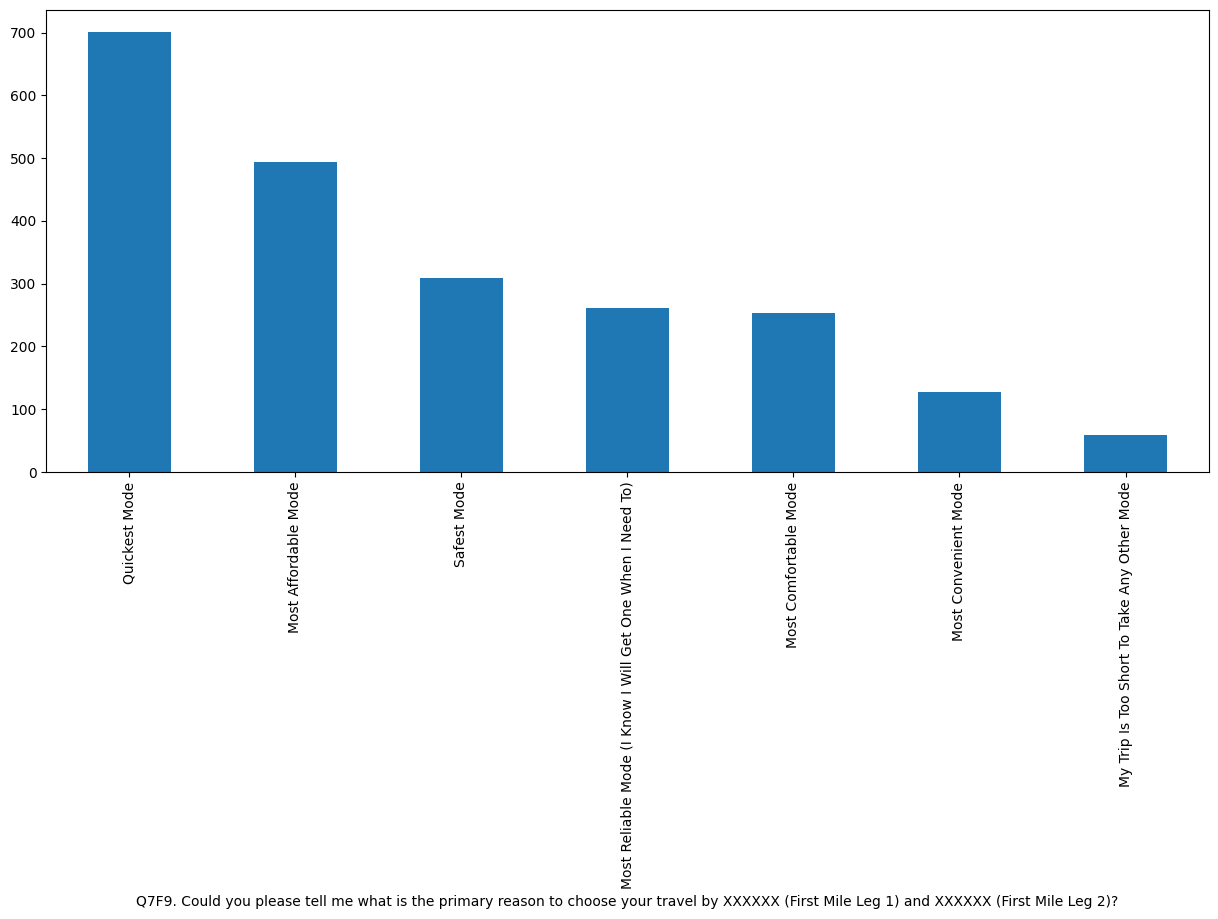

In [219]:
# Q7F9. Could you please tell me what is the primary reason to choose your travel by XXXXXX (First Mile Leg 1) and XXXXXX (First Mile Leg 2)?
column_name_reason_first_mile = 'Q7F9. Could you please tell me what is the primary reason to choose your travel by XXXXXX (First Mile Leg 1) and XXXXXX (First Mile Leg 2)?'

# Q7F10. Could you please tell me what is the secondary reason to choose your travel by XXXXXX (First Mile leg 1) and XXXXXX (First Mile leg 2)?
column_name_secondary_reason_first_mile = 'Q7F10. Could you please tell me what is the secondary reason to choose your travel by XXXXXX (First Mile leg 1) and XXXXXX (First Mile leg 2)?'

# Q7L9. Could you please tell me what is the primary travel reason to choose by XXXXXX (Last Mile Leg 1) and XXXXXX (Last Mile Leg 2)?
column_name_reason_last_mile = 'Q7L9. Could you please tell me what is the primary travel reason to choose by XXXXXX (Last Mile Leg 1) and XXXXXX (Last Mile Leg 2)?'

# Q7L10. Could you please tell me what is the secondary travel reason to choose by XXXXXX (Last Mile leg 1) and XXXXXX (Last Mile leg 2)?
column_name_secondary_reason_last_mile = 'Q7L10. Could you please tell me what is the secondary travel reason to choose by XXXXXX (Last Mile leg 1) and XXXXXX (Last Mile leg 2)?'



# Value counts
print(d[column_name_secondary_reason_last_mile].value_counts())
print(d[column_name_secondary_reason_first_mile].value_counts())
print(d[column_name_reason_last_mile].value_counts())
print(d[column_name_reason_first_mile].value_counts())

# Graphical representation
plt.figure(figsize=(15,6))
d[column_name_secondary_reason_last_mile].value_counts().plot(kind='bar')
plt.figure(figsize=(15,6))
d[column_name_secondary_reason_first_mile].value_counts().plot(kind='bar')
plt.figure(figsize=(15,6))
d[column_name_reason_last_mile].value_counts().plot(kind='bar')
plt.figure(figsize=(15,6))
d[column_name_reason_first_mile].value_counts().plot(kind='bar')

In [220]:
# Q7F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute
column_name_trip_time_first_mile_leg_1 = 'Q7F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute'
# Null values in trip time leg 1
null_values_trip_time_leg_1 = d[column_name_trip_time_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Trip time by first mile connection (Leg 1)': {null_values_trip_time_leg_1}")

# print(d[column_name_trip_time_first_mile_leg_1].describe())

# Values < 5 and greater 100
print(d[d[column_name_trip_time_first_mile_leg_1] < 2][column_name_trip_time_first_mile_leg_1].value_counts())
print(d[d[column_name_trip_time_first_mile_leg_1] > 30][column_name_trip_time_first_mile_leg_1].value_counts())


# Remove values < 2 and > 30
d1 = d[(d[column_name_trip_time_first_mile_leg_1] >= 2) & (d[column_name_trip_time_first_mile_leg_1] <= 30)]

print(d1[column_name_trip_time_first_mile_leg_1].describe())
mean_column_name_trip_time_first_mile_leg_1 = d1[column_name_trip_time_first_mile_leg_1].mean()
print(f"Mean of '{column_name_trip_time_first_mile_leg_1}': {mean_column_name_trip_time_first_mile_leg_1}")
median_column_name_trip_time_first_mile_leg_1 = d1[column_name_trip_time_first_mile_leg_1].median()
print(f"Median of '{column_name_trip_time_first_mile_leg_1}': {median_column_name_trip_time_first_mile_leg_1}")
mode_column_name_trip_time_first_mile_leg_1 = d1[column_name_trip_time_first_mile_leg_1].mode()[0]
print(f"Mode of '{column_name_trip_time_first_mile_leg_1}': {   mode_column_name_trip_time_first_mile_leg_1}")
variance_column_name_trip_time_first_mile_leg_1 = d1[column_name_trip_time_first_mile_leg_1].var()
print(f"Variance of '{column_name_trip_time_first_mile_leg_1}': {variance_column_name_trip_time_first_mile_leg_1}")
print(len(d1), len(d))

Number of null values in 'Trip time by first mile connection (Leg 1)': 0
Q7F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute
0    1
Name: count, dtype: int64
Q7F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute
35     6
32     3
60     2
70     1
120    1
90     1
45     1
Name: count, dtype: int64
count    2189.000000
mean       10.459571
std         5.407764
min         2.000000
25%         6.000000
50%        10.000000
75%        15.000000
max        30.000000
Name: Q7F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute, dtype: float64
Mean of 'Q7F1.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip time in minute': 10.459570580173596
Median of 'Q7F1.  How many minutes is your trip by xxxx (mentioned automatically)

In [221]:
# Q7F5.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip time in minute
column_name_trip_time_First_mile_leg_2 = 'Q7F5.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip time in minute'
# Null values in trip time leg 2
null_values_trip_time_leg_2 = d1[column_name_trip_time_First_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by first mile connection (Leg 2)': {null_values_trip_time_leg_2}")

for index, row in d1.iterrows():
    if row[column_name_First_mile_leg_2] == "No First mile leg 2":
        d1.at[index, column_name_trip_time_First_mile_leg_2] = 0

null_values_trip_time_leg_2_after = d1[column_name_trip_time_First_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by first mile connection (Leg 2)' after filling: {null_values_trip_time_leg_2_after}")


print(d1[column_name_trip_time_First_mile_leg_2].describe())
mean_column_name_trip_time_First_mile_leg_2 = d1[column_name_trip_time_First_mile_leg_2].mean()
print(f"Mean of '{column_name_trip_time_First_mile_leg_2}': {mean_column_name_trip_time_First_mile_leg_2}")
median_column_name_trip_time_First_mile_leg_2 = d1[column_name_trip_time_First_mile_leg_2].median()
print(f"Median of '{column_name_trip_time_First_mile_leg_2}': {median_column_name_trip_time_First_mile_leg_2}")
mode_column_name_trip_time_First_mile_leg_2 = d1[column_name_trip_time_First_mile_leg_2].mode()[0]
print(f"Mode of '{column_name_trip_time_First_mile_leg_2}': {mode_column_name_trip_time_First_mile_leg_2}")
variance_column_name_trip_time_First_mile_leg_2 = d1[column_name_trip_time_First_mile_leg_2].var()
print(f"Variance of '{column_name_trip_time_First_mile_leg_2}': {variance_column_name_trip_time_First_mile_leg_2}")

Number of null values in 'Trip time by first mile connection (Leg 2)': 1979
Number of null values in 'Trip time by first mile connection (Leg 2)' after filling: 0
count    2189.000000
mean        0.957515
std         3.374754
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        25.000000
Name: Q7F5.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip time in minute, dtype: float64
Mean of 'Q7F5.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip time in minute': 0.9575148469620831
Median of 'Q7F5.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip time in minute': 0.0
Mode of 'Q7F5.  How many minutes is your trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip time in minute': 0.0
Variance of 'Q7F5.  How many minutes is your trip by xxxx (mentioned automaticall

In [222]:
# Mode Share in First Mile Connectivity
d1['First Mile Mode Sharing'] = d1[column_name_first_mile_leg_1] + ' + ' + d1[column_name_First_mile_leg_2]
first_mile_mode_share = d1['First Mile Mode Sharing'].value_counts()
print(first_mile_mode_share)

# Mode Share Trip Time in First Mile Connectivity
d1['First Mile Mode share Trip Time'] = d1[column_name_trip_time_first_mile_leg_1] + d1[column_name_trip_time_First_mile_leg_2]


First Mile Mode Sharing
Walk + No First mile leg 2           1447
Auto + No First mile leg 2            282
Two-wheeler + No First mile leg 2     169
Walk + Auto                            92
Walk + Two-wheeler                     50
Others + No First mile leg 2           39
Car/Taxi + No First mile leg 2         23
Cycle + No First mile leg 2            19
Walk + Cycle                           19
Two-wheeler + Walk                     14
Auto + Walk                            10
Walk + Car/Taxi                         8
Walk + Others                           8
Others + Walk                           3
Cycle + Walk                            2
Cycle + Auto                            1
Car/Taxi + Walk                         1
Auto + Others                           1
Two-wheeler + Auto                      1
Name: count, dtype: int64


C:\Users\maddi\AppData\Local\Temp\ipykernel_13664\1102797728.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d1['First Mile Mode Sharing'] = d1[column_name_first_mile_leg_1] + ' + ' + d1[column_name_First_mile_leg_2]
C:\Users\maddi\AppData\Local\Temp\ipykernel_13664\1102797728.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d1['First Mile Mode share Trip Time'] = d1[column_name_trip_time_first_mile_leg_1] + d1[column_name_trip_time_First_mile_leg_2]


In [223]:
# Q7P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute
column_name_trip_time_primary_leg_1 = 'Q7P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute'
# Null values in trip time primary leg 1
null_values_trip_time_primary_leg_1 = d1[column_name_trip_time_primary_leg_1].isnull().sum()
print(f"Number of null values in 'Trip time by primary leg 1': {null_values_trip_time_primary_leg_1}")



for mode in d1[column_name_primary_mode_leg_1].unique():
    mode_filter = d1[column_name_primary_mode_leg_1] == mode
    mode_data = d1[mode_filter]
    mean_trip_time = mode_data[column_name_trip_time_primary_leg_1].mean()
    d1.loc[mode_filter & d1[column_name_trip_time_primary_leg_1].isnull(), column_name_trip_time_primary_leg_1] = mean_trip_time

# Count values <5 and >60
print(d1[d1[column_name_trip_time_primary_leg_1] < 5][column_name_trip_time_primary_leg_1].value_counts())
print(d1[d1[column_name_trip_time_primary_leg_1] > 60][column_name_trip_time_primary_leg_1].value_counts())

# Remove values < 5 and > 60
d1 = d1[(d1[column_name_trip_time_primary_leg_1] >= 5) & (d1[column_name_trip_time_primary_leg_1] <= 60)]

print(d1[column_name_trip_time_primary_leg_1].describe())
mean_column_name_trip_time_primary_leg_1 = d1[column_name_trip_time_primary_leg_1].mean()
print(f"Mean of '{column_name_trip_time_primary_leg_1}': {mean_column_name_trip_time_primary_leg_1}")
median_column_name_trip_time_primary_leg_1 = d1[column_name_trip_time_primary_leg_1].median()
print(f"Median of '{column_name_trip_time_primary_leg_1}': {median_column_name_trip_time_primary_leg_1}")
mode_column_name_trip_time_primary_leg_1 = d1[column_name_trip_time_primary_leg_1].mode()[0]
print(f"Mode of '{column_name_trip_time_primary_leg_1}': {mode_column_name_trip_time_primary_leg_1}")
variance_column_name_trip_time_primary_leg_1 = d1[column_name_trip_time_primary_leg_1].var()
print(f"Variance of '{column_name_trip_time_primary_leg_1}': {variance_column_name_trip_time_primary_leg_1}")


Number of null values in 'Trip time by primary leg 1': 989
Q7P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute
1.0    5
4.0    4
3.0    3
2.0    2
Name: count, dtype: int64
Q7P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute
155.0    1
90.0     1
Name: count, dtype: int64
count    2173.000000
mean       25.958260
std         9.660834
min         5.000000
25%        25.000000
50%        26.047826
75%        26.047826
max        60.000000
Name: Q7P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute, dtype: float64
Mean of 'Q7P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute': 25.95826046939715
Median of 'Q7P1. How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 1 - Trip time in minute': 26.047826086956523
Mode of 'Q7P1. How many minutes in 

In [224]:
# Q7P5.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Trip time in minute
column_name_trip_time_primary_leg_2 = 'Q7P5.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Trip time in minute'
# Null values in trip time primary leg 2
null_values_trip_time_primary_leg_2 = d1[column_name_trip_time_primary_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by primary leg 2': {null_values_trip_time_primary_leg_2}")

for index, row in d1.iterrows():
    if row[column_name_primary_mode_leg_2] == "No Primary mode leg 2":
        d1.at[index, column_name_trip_time_primary_leg_2] = 0
null_values_trip_time_primary_leg_2_after = d1[column_name_trip_time_primary_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by primary leg 2' after filling: {null_values_trip_time_primary_leg_2_after}")

for mode in d1[column_name_primary_mode_leg_2].unique():
    mode_filter = d1[column_name_primary_mode_leg_2] == mode
    mode_data = d1[mode_filter]
    mean_trip_time = mode_data[column_name_trip_time_primary_leg_2].mean()
    d1.loc[mode_filter & d1[column_name_trip_time_primary_leg_2].isnull(), column_name_trip_time_primary_leg_2] = mean_trip_time


null_values_trip_time_primary_leg_2_after = d1[column_name_trip_time_primary_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by primary leg 2' after filling: {null_values_trip_time_primary_leg_2_after}")


print(d1[column_name_trip_time_primary_leg_2].describe())
mean_column_name_trip_time_primary_leg_2 = d1[column_name_trip_time_primary_leg_2].mean()
print(f"Mean of '{column_name_trip_time_primary_leg_2}': {mean_column_name_trip_time_primary_leg_2}")
median_column_name_trip_time_primary_leg_2 = d1[column_name_trip_time_primary_leg_2].median()
print(f"Median of '{column_name_trip_time_primary_leg_2}': {median_column_name_trip_time_primary_leg_2}")
mode_column_name_trip_time_primary_leg_2 = d1[column_name_trip_time_primary_leg_2].mode()[0]
print(f"Mode of '{column_name_trip_time_primary_leg_2}': {mode_column_name_trip_time_primary_leg_2}")
variance_column_name_trip_time_primary_leg_2 = d1[column_name_trip_time_primary_leg_2].var()
print(f"Variance of '{column_name_trip_time_primary_leg_2}': {variance_column_name_trip_time_primary_leg_2}")

Number of null values in 'Trip time by primary leg 2': 1895
Number of null values in 'Trip time by primary leg 2' after filling: 11
Number of null values in 'Trip time by primary leg 2' after filling: 0
count    2173.000000
mean        2.622833
std         7.616059
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        60.000000
Name: Q7P5.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Trip time in minute, dtype: float64
Mean of 'Q7P5.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Trip time in minute': 2.6228332566344528
Median of 'Q7P5.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Trip time in minute': 0.0
Mode of 'Q7P5.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Trip time in minute': 0.0
Variance of 'Q7P5.  How many minutes in your trip by xxxx (mentioned automatically)? - Primary Leg 2 - Tr

In [225]:
# Mode Share in Primary Connectivity
d1['Primary Mode Sharing'] = d1[column_name_primary_mode_leg_1] + ' + ' + d1[column_name_primary_mode_leg_2]
primary_mode_share = d1['Primary Mode Sharing'].value_counts()

d1['Primary Mode share Trip Time'] = d1[column_name_trip_time_primary_leg_1] + d1[column_name_trip_time_primary_leg_2]


In [226]:
# Q7L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip time in minute
column_name_trip_time_last_mile_leg_1 = 'Q7L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip time in minute'
# Null values in trip time last mile leg 1
null_values_trip_time_last_mile_leg_1 = d1[column_name_trip_time_last_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Trip time by last mile connection (Leg 1)': {null_values_trip_time_last_mile_leg_1}")



# Values < 2 and > 30
print(d1[d1[column_name_trip_time_last_mile_leg_1] < 2][column_name_trip_time_last_mile_leg_1].value_counts())
print(d1[d1[column_name_trip_time_last_mile_leg_1] > 30][column_name_trip_time_last_mile_leg_1].value_counts())

# Remove values < 2 and > 30
d1 = d1[(d1[column_name_trip_time_last_mile_leg_1] >= 2) & (d1[column_name_trip_time_last_mile_leg_1] <= 30)]

print(d1[column_name_trip_time_last_mile_leg_1].describe())
mean_column_name_trip_time_last_mile_leg_1 = d1[column_name_trip_time_last_mile_leg_1].mean()
print(f"Mean of '{column_name_trip_time_last_mile_leg_1}': {mean_column_name_trip_time_last_mile_leg_1}")
median_column_name_trip_time_last_mile_leg_1 = d1[column_name_trip_time_last_mile_leg_1].median()
print(f"Median of '{column_name_trip_time_last_mile_leg_1}': {median_column_name_trip_time_last_mile_leg_1}")
mode_column_name_trip_time_last_mile_leg_1 = d1[column_name_trip_time_last_mile_leg_1].mode()[0]
print(f"Mode of '{column_name_trip_time_last_mile_leg_1}': {mode_column_name_trip_time_last_mile_leg_1}")
variance_column_name_trip_time_last_mile_leg_1 = d1[column_name_trip_time_last_mile_leg_1].var()
print(f"Variance of '{column_name_trip_time_last_mile_leg_1}': {variance_column_name_trip_time_last_mile_leg_1}")

Number of null values in 'Trip time by last mile connection (Leg 1)': 0
Q7L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip time in minute
0    2
Name: count, dtype: int64
Q7L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip time in minute
35     7
32     2
38     2
100    1
42     1
44     1
Name: count, dtype: int64
count    2157.000000
mean       10.190542
std         5.147936
min         2.000000
25%         6.000000
50%        10.000000
75%        14.000000
max        30.000000
Name: Q7L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip time in minute, dtype: float64
Mean of 'Q7L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip time in minute': 10.190542420027816
Median of 'Q7L1.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile 

In [227]:
# Q7L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute
column_name_trip_time_last_mile_leg_2 = 'Q7L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute'
d2 = d1.copy()

# Null values in trip time last mile leg 2
null_values_trip_time_last_mile_leg_2 = d2[column_name_trip_time_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by last mile connection (Leg 2)': {null_values_trip_time_last_mile_leg_2}")

for index, row in d2.iterrows():
    if row[column_name_last_mile_leg_2] == "No Last mile leg 2":
        d2.at[index, column_name_trip_time_last_mile_leg_2] = 0
        

print(d2[column_name_trip_time_last_mile_leg_2].describe())
mean_column_name_trip_time_first_mile_leg_12 = d2[column_name_trip_time_last_mile_leg_2].mean()
print(f"Mean of '{column_name_trip_time_last_mile_leg_2}': {mean_column_name_trip_time_first_mile_leg_12}")
median_column_name_trip_time_first_mile_leg_12 = d2[column_name_trip_time_last_mile_leg_2].median()
print(f"Median of '{column_name_trip_time_last_mile_leg_2}': {median_column_name_trip_time_first_mile_leg_12}")
mode_column_name_trip_time_first_mile_leg_12 = d2[column_name_trip_time_last_mile_leg_2].mode()[0]
print(f"Mode of '{column_name_trip_time_last_mile_leg_2}': {mode_column_name_trip_time_first_mile_leg_12}")
variance_column_name_trip_time_first_mile_leg_12 = d2[column_name_trip_time_last_mile_leg_2].var()
print(f"Variance of '{column_name_trip_time_last_mile_leg_2}': {variance_column_name_trip_time_first_mile_leg_12}")


Number of null values in 'Trip time by last mile connection (Leg 2)': 2088
count    2157.000000
mean        0.277701
std         1.723280
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        25.000000
Name: Q7L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute, dtype: float64
Mean of 'Q7L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute': 0.2777005099675475
Median of 'Q7L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute': 0.0
Mode of 'Q7L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute': 0.0
Variance of 'Q7L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute': 2.969692669076734


In [228]:
# Mode share in Last Mile Connectivity
d2['Last Mile Mode Sharing'] = d2[column_name_last_mile_leg_1] + ' + ' + d2[column_name_last_mile_leg_2]
last_mile_mode_share = d2['Last Mile Mode Sharing'].value_counts()

d2['Last Mile Mode share Trip Time'] = d2[column_name_trip_time_last_mile_leg_1] + d2[column_name_trip_time_last_mile_leg_2]

value_counts_last_mile_mode = d2['Last Mile Mode Sharing'].value_counts()
print(value_counts_last_mile_mode)

Last Mile Mode Sharing
Walk + No Last mile leg 2           1762
Auto + No Last mile leg 2            239
Others + No Last mile leg 2           29
Auto + Walk                           27
Two-wheeler + No Last mile leg 2      23
Car/Taxi + No Last mile leg 2         21
Walk + Auto                           14
Cycle + No Last mile leg 2            14
Walk + Cycle                           8
Cycle + Walk                           7
Others + Walk                          3
Walk + Two-wheeler                     3
Two-wheeler + Walk                     2
Walk + Others                          2
Car/Taxi + Walk                        1
Walk + Car/Taxi                        1
Others + Auto                          1
Name: count, dtype: int64


In [229]:
# Q7F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection (Leg 1) - Wait time in minute

column_name_wait_time_first_mile_leg_1 = 'Q7F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection (Leg 1) - Wait time in minute'
# Null values in wait time first mile leg 1
null_values_wait_time_first_mile_leg_1 = d2[column_name_wait_time_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Wait time for first mile connection (Leg 1)': {null_values_wait_time_first_mile_leg_1}")


null_values_wait_time_first_mile_leg_1_after = d2[column_name_wait_time_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Wait time for first mile connection (Leg 1)' after filling: {null_values_wait_time_first_mile_leg_1_after}")

# FIll null values with mean
d2[column_name_wait_time_first_mile_leg_1].fillna(d2[column_name_wait_time_first_mile_leg_1].mean(), inplace=True)



# Values < 1 and > 15
print(d2[d2[column_name_wait_time_first_mile_leg_1] < 1][column_name_wait_time_first_mile_leg_1].value_counts())
print(d2[d2[column_name_wait_time_first_mile_leg_1] > 15][column_name_wait_time_first_mile_leg_1].value_counts())

# Remove values < 1 and > 15
d2 = d2[(d2[column_name_wait_time_first_mile_leg_1] >= 1) & (d2[column_name_wait_time_first_mile_leg_1] <= 15)]

print(d2[column_name_wait_time_first_mile_leg_1].describe())
mean_column_name_wait_time_first_mile_leg_1 = d2[column_name_wait_time_first_mile_leg_1].mean()
print(f"Mean of '{column_name_wait_time_first_mile_leg_1}': {mean_column_name_wait_time_first_mile_leg_1}")
median_column_name_wait_time_first_mile_leg_1 = d2[column_name_wait_time_first_mile_leg_1].median()
print(f"Median of '{column_name_wait_time_first_mile_leg_1}': {median_column_name_wait_time_first_mile_leg_1}")
mode_column_name_wait_time_first_mile_leg_1 = d2[column_name_wait_time_first_mile_leg_1].mode()[0]
print(f"Mode of '{column_name_wait_time_first_mile_leg_1}': {mode_column_name_wait_time_first_mile_leg_1}")
variance_column_name_wait_time_first_mile_leg_1 = d2[column_name_wait_time_first_mile_leg_1].var()
print(f"Variance of '{column_name_wait_time_first_mile_leg_1}': {variance_column_name_wait_time_first_mile_leg_1}")


Number of null values in 'Wait time for first mile connection (Leg 1)': 1796
Number of null values in 'Wait time for first mile connection (Leg 1)' after filling: 1796
Q7F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection (Leg 1) - Wait time in minute
0.0    1
Name: count, dtype: int64
Q7F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection (Leg 1) - Wait time in minute
20.0    3
25.0    2
30.0    1
22.0    1
17.0    1
Name: count, dtype: int64
count    2148.000000
mean        7.563531
std         1.452727
min         1.000000
25%         7.614958
50%         7.614958
75%         7.614958
max        15.000000
Name: Q7F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection (Leg 1) - Wait time in minute, dtype: float64
Mean of 'Q7F2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - First mile connection 

C:\Users\maddi\AppData\Local\Temp\ipykernel_13664\588726228.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d2[column_name_wait_time_first_mile_leg_1].fillna(d2[column_name_wait_time_first_mile_leg_1].mean(), inplace=True)


In [230]:
# Q7F6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)?  - First mile connection (Leg 2) - Wait time in minute
column_name_wait_time_first_mile_leg_2 = 'Q7F6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)?  - First mile connection (Leg 2) - Wait time in minute'
# Null values in wait time first mile leg 2
null_values_wait_time_first_mile_leg_2 = d2[column_name_wait_time_first_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Wait time for first mile connection (Leg 2)': {null_values_wait_time_first_mile_leg_2}")

for index, row in d2.iterrows():
    if row[column_name_First_mile_leg_2] == "No First mile leg 2":
        d2.at[index, column_name_wait_time_first_mile_leg_2] = 0

null_values_wait_time_first_mile_leg_2_after = d2[column_name_wait_time_first_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Wait time for first mile connection (Leg 2)' after filling: {null_values_wait_time_first_mile_leg_2_after}")


# FIll null values with mean
d2[column_name_wait_time_first_mile_leg_2].fillna(d2[column_name_wait_time_first_mile_leg_2].mean(), inplace=True)

print(d2[column_name_wait_time_first_mile_leg_2].describe())
mean_column_name_wait_time_first_mile_leg_2 = d2[column_name_wait_time_first_mile_leg_2].mean()
print(f"Mean of '{column_name_wait_time_first_mile_leg_2}': {mean_column_name_wait_time_first_mile_leg_2}")
median_column_name_wait_time_first_mile_leg_2 = d2[column_name_wait_time_first_mile_leg_2].median()
print(f"Median of '{column_name_wait_time_first_mile_leg_2}': {median_column_name_wait_time_first_mile_leg_2}")
mode_column_name_wait_time_first_mile_leg_2 = d2[column_name_wait_time_first_mile_leg_2].mode()[0]
print(f"Mode of '{column_name_wait_time_first_mile_leg_2}': {mode_column_name_wait_time_first_mile_leg_2}")
variance_column_name_wait_time_first_mile_leg_2 = d2[column_name_wait_time_first_mile_leg_2].var()
print(f"Variance of '{column_name_wait_time_first_mile_leg_2}': {variance_column_name_wait_time_first_mile_leg_2}")

Number of null values in 'Wait time for first mile connection (Leg 2)': 2041
Number of null values in 'Wait time for first mile connection (Leg 2)' after filling: 102
count    2148.000000
mean        0.350929
std         1.567609
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        20.000000
Name: Q7F6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)?  - First mile connection (Leg 2) - Wait time in minute, dtype: float64
Mean of 'Q7F6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)?  - First mile connection (Leg 2) - Wait time in minute': 0.35092864125122186
Median of 'Q7F6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)?  - First mile connection (Leg 2) - Wait time in minute': 0.0
Mode of 'Q7F6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)?  - First mile connection (Leg 2) - Wait time in minute': 0.0
Variance of 'Q7F6.  How 

C:\Users\maddi\AppData\Local\Temp\ipykernel_13664\3514614050.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d2[column_name_wait_time_first_mile_leg_2].fillna(d2[column_name_wait_time_first_mile_leg_2].mean(), inplace=True)


In [231]:
# Mode share in First Mile Connectivity - Wait Time
d2['First Mile Mode share Wait Time'] = d2[column_name_wait_time_first_mile_leg_1] + d2[column_name_wait_time_first_mile_leg_2]

In [232]:
# Q7P2. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 1 - Wait time in minute
column_name_wait_time_primary_leg_1 = 'Q7P2. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 1 - Wait time in minute'
# Null values in wait time primary leg 1
null_values_wait_time_primary_leg_1 = d2[column_name_wait_time_primary_leg_1].isnull().sum()
print(f"Number of null values in 'Wait time for primary leg 1': {null_values_wait_time_primary_leg_1}")

print(d2[column_name_wait_time_primary_leg_1].describe())

# Values < 1 and > 30
print(d2[d2[column_name_wait_time_primary_leg_1] < 1][column_name_wait_time_primary_leg_1].value_counts())
print(d2[d2[column_name_wait_time_primary_leg_1] > 30][column_name_wait_time_primary_leg_1].value_counts())

# Remove values < 1 and > 30
d2 = d2[(d2[column_name_wait_time_primary_leg_1] >= 1) & (d2[column_name_wait_time_primary_leg_1] <= 30)]

print(d2[column_name_wait_time_primary_leg_1].describe())
mean_column_name_wait_time_primary_leg_1 = d2[column_name_wait_time_primary_leg_1].mean()
print(f"Mean of '{column_name_wait_time_primary_leg_1}': {mean_column_name_wait_time_primary_leg_1}")
median_column_name_wait_time_primary_leg_1 = d2[column_name_wait_time_primary_leg_1].median()
print(f"Median of '{column_name_wait_time_primary_leg_1}': {median_column_name_wait_time_primary_leg_1}")
mode_column_name_wait_time_primary_leg_1 = d2[column_name_wait_time_primary_leg_1].mode()[0]
print(f"Mode of '{column_name_wait_time_primary_leg_1}': {mode_column_name_wait_time_primary_leg_1}")
variance_column_name_wait_time_primary_leg_1 = d2[column_name_wait_time_primary_leg_1].var()
print(f"Variance of '{column_name_wait_time_primary_leg_1}': {variance_column_name_wait_time_primary_leg_1}")

Number of null values in 'Wait time for primary leg 1': 0
count    2148.000000
mean        6.885009
std         3.366220
min         0.000000
25%         5.000000
50%         6.000000
75%         8.000000
max        45.000000
Name: Q7P2. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 1 - Wait time in minute, dtype: float64
Q7P2. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 1 - Wait time in minute
0    4
Name: count, dtype: int64
Q7P2. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 1 - Wait time in minute
45    1
40    1
Name: count, dtype: int64
count    2142.000000
mean        6.864613
std         3.175450
min         1.000000
25%         5.000000
50%         6.000000
75%         8.000000
max        30.000000
Name: Q7P2. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 1 - Wait time in minute, dtype: float64
Mea

In [233]:
# Q7P6. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 2 - Wait time in minute
column_name_wait_time_primary_leg_2 = 'Q7P6. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 2 - Wait time in minute'
# Null values in wait time primary leg 2
null_values_wait_time_primary_leg_2 = d2[column_name_wait_time_primary_leg_2].isnull().sum()
print(f"Number of null values in 'Wait time for primary leg 2': {null_values_wait_time_primary_leg_2}")

for index, row in d2.iterrows():
    if row[column_name_primary_mode_leg_2] == "No Primary mode leg 2":
        d2.at[index, column_name_wait_time_primary_leg_2] = 0

null_values_wait_time_primary_leg_2_after = d2[column_name_wait_time_primary_leg_2].isnull().sum()
print(f"Number of null values in 'Wait time for primary leg 2' after filling: {null_values_wait_time_primary_leg_2_after}")


print(d2[column_name_wait_time_primary_leg_2].describe())

Number of null values in 'Wait time for primary leg 2': 1855
Number of null values in 'Wait time for primary leg 2' after filling: 0
count    2142.000000
mean        1.002801
std         2.781804
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        20.000000
Name: Q7P6. How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Primary Leg 2 - Wait time in minute, dtype: float64


In [234]:
# Mode Share in Primary Connectivity - Wait Time
d2['Primary Mode share Wait Time'] = d2[column_name_wait_time_primary_leg_1] + d2[column_name_wait_time_primary_leg_2]

In [235]:
# Q7L2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 1) - Wait time in minute
column_name_wait_time_last_mile_leg_1 = 'Q7L2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 1) - Wait time in minute'
# Null values in wait time last mile leg 1
null_values_wait_time_last_mile_leg_1 = d2[column_name_wait_time_last_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Wait time for last mile connection (Leg 1 )': {null_values_wait_time_last_mile_leg_1}")

print(d2[column_name_wait_time_last_mile_leg_1].describe())

# Fill with mean
d2[column_name_wait_time_last_mile_leg_1].fillna(d2[column_name_wait_time_last_mile_leg_1].mean(), inplace=True)

# Values < 1 and > 20
print(d2[d2[column_name_wait_time_last_mile_leg_1] < 1][column_name_wait_time_last_mile_leg_1].value_counts())
print(d2[d2[column_name_wait_time_last_mile_leg_1] > 20][column_name_wait_time_last_mile_leg_1].value_counts())

# Remove values < 1 and > 20
d2 = d2[(d2[column_name_wait_time_last_mile_leg_1] >= 1) & (d2[column_name_wait_time_last_mile_leg_1] <= 20)]
print(d2[column_name_wait_time_last_mile_leg_1].describe())
mean_column_name_wait_time_last_mile_leg_1 = d2[column_name_wait_time_last_mile_leg_1].mean()
print(f"Mean of '{column_name_wait_time_last_mile_leg_1}': {mean_column_name_wait_time_last_mile_leg_1}")
median_column_name_wait_time_last_mile_leg_1 = d2[column_name_wait_time_last_mile_leg_1].median()
print(f"Median of '{column_name_wait_time_last_mile_leg_1}': {median_column_name_wait_time_last_mile_leg_1}")
mode_column_name_wait_time_last_mile_leg_1 = d2[column_name_wait_time_last_mile_leg_1].mode()[0]
print(f"Mode of '{column_name_wait_time_last_mile_leg_1}': {mode_column_name_wait_time_last_mile_leg_1}")
variance_column_name_wait_time_last_mile_leg_1 = d2[column_name_wait_time_last_mile_leg_1].var()
print(f"Variance of '{column_name_wait_time_last_mile_leg_1}': {variance_column_name_wait_time_last_mile_leg_1}")


Number of null values in 'Wait time for last mile connection (Leg 1 )': 1806
count    336.000000
mean       8.110119
std        4.325187
min        0.000000
25%        5.000000
50%        6.500000
75%       10.000000
max       23.000000
Name: Q7L2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 1) - Wait time in minute, dtype: float64
Q7L2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 1) - Wait time in minute
0.0    2
Name: count, dtype: int64
Q7L2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 1) - Wait time in minute
23.0    1
Name: count, dtype: int64
count    2139.000000
mean        8.110741
std         1.663124
min         2.000000
25%         8.110119
50%         8.110119
75%         8.110119
max        20.000000
Name: Q7L2.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? -

C:\Users\maddi\AppData\Local\Temp\ipykernel_13664\233779407.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d2[column_name_wait_time_last_mile_leg_1].fillna(d2[column_name_wait_time_last_mile_leg_1].mean(), inplace=True)


In [236]:
#Q7L6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 2) - Wait time in minute

column_name_wait_time_last_mile_leg_2 = 'Q7L6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 2) - Wait time in minute'
# Null values in wait time last mile leg 2
null_values_wait_time_last_mile_leg_2 = d2[column_name_wait_time_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Wait time for last mile connection (Leg 2)': {null_values_wait_time_last_mile_leg_2}")


for index, row in d2.iterrows():
    if row[column_name_last_mile_leg_2] == "No Last mile leg 2":
        d2.at[index, column_name_wait_time_last_mile_leg_2] = 0

null_values_wait_time_last_mile_leg_2_after = d2[column_name_wait_time_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Wait time for last mile connection (Leg 2)' after filling: {null_values_wait_time_last_mile_leg_2_after}")


# Fill with mean
d2[column_name_wait_time_last_mile_leg_2].fillna(d2[column_name_wait_time_last_mile_leg_2].mean(), inplace=True)

print(d2[column_name_wait_time_last_mile_leg_2].describe())
mean_column_name_wait_time_last_mile_leg_2 = d2[column_name_wait_time_last_mile_leg_2].mean()

print(f"Mean of '{column_name_wait_time_last_mile_leg_2}': {mean_column_name_wait_time_last_mile_leg_2}")
median_column_name_wait_time_last_mile_leg_2 = d2[column_name_wait_time_last_mile_leg_2].median()
print(f"Median of '{column_name_wait_time_last_mile_leg_2}': {median_column_name_wait_time_last_mile_leg_2}")
mode_column_name_wait_time_last_mile_leg_2 = d2[column_name_wait_time_last_mile_leg_2].mode()[0]
print(f"Mode of '{column_name_wait_time_last_mile_leg_2}': {mode_column_name_wait_time_last_mile_leg_2}")
variance_column_name_wait_time_last_mile_leg_2 = d2[column_name_wait_time_last_mile_leg_2].var()
print(f"Variance of '{column_name_wait_time_last_mile_leg_2}': {variance_column_name_wait_time_last_mile_leg_2}")


Number of null values in 'Wait time for last mile connection (Leg 2)': 2116
Number of null values in 'Wait time for last mile connection (Leg 2)' after filling: 44
count    2139.000000
mean        0.071122
std         0.754904
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        12.000000
Name: Q7L6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 2) - Wait time in minute, dtype: float64
Mean of 'Q7L6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 2) - Wait time in minute': 0.0711217183770883
Median of 'Q7L6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 2) - Wait time in minute': 0.0
Mode of 'Q7L6.  How many minutes do you spend on waiting for xxxx (mentioned automatically)? - Last mile connection (leg 2) - Wait time in minute': 0.0
Variance of 'Q7L6.  How many minutes

C:\Users\maddi\AppData\Local\Temp\ipykernel_13664\2626424085.py:18: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d2[column_name_wait_time_last_mile_leg_2].fillna(d2[column_name_wait_time_last_mile_leg_2].mean(), inplace=True)


In [237]:
# Mode share in Last Mile Connectivity - Wait Time
d2['Last Mile Mode share Wait Time'] = d2[column_name_wait_time_last_mile_leg_1] + d2[column_name_wait_time_last_mile_leg_2]


len(d2)

2139

In [238]:
# Q7F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip Cost (In Rupees) :
column_name_trip_cost_first_mile_leg_1 = 'Q7F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip Cost (In Rupees) :'

# Q7F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Monthly Fuel Cost (Petrol/Diesel) (In Rupees) :
column_name_monthly_fuel_cost_first_mile_leg_1 = 'Q7F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Monthly Fuel Cost (Petrol/Diesel) (In Rupees) :'


# Null values in trip cost first mile leg 1
null_values_trip_cost_first_mile_leg_1 = d2[column_name_trip_cost_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Trip cost for first mile connection (Leg 1)': {null_values_trip_cost_first_mile_leg_1}")





modes_with_nulls = d2.loc[d2[column_name_trip_cost_first_mile_leg_1].isnull(), column_name_first_mile_leg_1].unique()
print(modes_with_nulls)

mean_2wheeler = d2.loc[d2[column_name_first_mile_leg_1]=='Two-wheeler', column_name_monthly_fuel_cost_first_mile_leg_1].mean()
mean_4wheeler = d2.loc[d2[column_name_first_mile_leg_1]=='Car/Taxi', column_name_monthly_fuel_cost_first_mile_leg_1].mean()

print(f"Mean trip cost for Two-Wheeler: {mean_2wheeler}")
print(f"Mean trip cost for Car/Taxi: {mean_4wheeler}")


for mode in d2[column_name_first_mile_leg_1].unique():

    mode_filter = d2[column_name_first_mile_leg_1] == mode

    if mode == "Walk":
        d2.loc[mode_filter & d2[column_name_trip_cost_first_mile_leg_1].isnull(), column_name_trip_cost_first_mile_leg_1] = 0

    if mode == 'Two-wheeler':
        d2.loc[mode_filter & d2[column_name_trip_cost_first_mile_leg_1].isnull(), column_name_trip_cost_first_mile_leg_1] = mean_2wheeler/30

    if mode == 'Car/Taxi':
        d2.loc[mode_filter & d2[column_name_trip_cost_first_mile_leg_1].isnull(), column_name_trip_cost_first_mile_leg_1] = mean_4wheeler/30




null_values_trip_cost_first_mile_leg_1_after = d2[column_name_trip_cost_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Trip cost for first mile connection (Leg 1)' after filling: {null_values_trip_cost_first_mile_leg_1_after}")

# Values >200
print(d2[d2[column_name_trip_cost_first_mile_leg_1] > 200][column_name_trip_cost_first_mile_leg_1].value_counts())

# Remove values > 200
d2 = d2[d2[column_name_trip_cost_first_mile_leg_1] <= 200]



print(d2[column_name_trip_cost_first_mile_leg_1].describe())
mean_column_name_trip_cost_first_mile_leg_1 = d2[column_name_trip_cost_first_mile_leg_1].mean()
print(f"Mean of '{column_name_trip_cost_first_mile_leg_1}': {mean_column_name_trip_cost_first_mile_leg_1}")
median_column_name_trip_cost_first_mile_leg_1 = d2[column_name_trip_cost_first_mile_leg_1].median()
print(f"Median of '{column_name_trip_cost_first_mile_leg_1}': {median_column_name_trip_cost_first_mile_leg_1}")
mode_column_name_trip_cost_first_mile_leg_1 = d2[column_name_trip_cost_first_mile_leg_1].mode()[0]
print(f"Mode of '{column_name_trip_cost_first_mile_leg_1}': {mode_column_name_trip_cost_first_mile_leg_1}")
variance_column_name_trip_cost_first_mile_leg_1 = d2[column_name_trip_cost_first_mile_leg_1].var()
print(f"Variance of '{column_name_trip_cost_first_mile_leg_1}': {variance_column_name_trip_cost_first_mile_leg_1}")

Number of null values in 'Trip cost for first mile connection (Leg 1)': 1768
['Walk' 'Two-wheeler' 'Car/Taxi']
Mean trip cost for Two-Wheeler: 1329.2235294117647
Mean trip cost for Car/Taxi: 4875.0
Number of null values in 'Trip cost for first mile connection (Leg 1)' after filling: 0
Q7F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip Cost (In Rupees) :
250.0     3
350.0     2
400.0     1
1500.0    1
1000.0    1
Name: count, dtype: int64
count    2131.000000
mean       11.252120
std        26.113082
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       200.000000
Name: Q7F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip Cost (In Rupees) :, dtype: float64
Mean of 'Q7F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip Cost (In Rupees) :': 11.25211950570937
Median of 

In [239]:
# Q7F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip Cost (In Rupees) :
column_name_trip_cost_first_mile_leg_2 = 'Q7F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip Cost (In Rupees) :'

#Q7F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Monthly Fuel Cost (Petrol/Diesel) (In Rupees) :
column_name_monthly_fuel_cost_first_mile_leg_2 = 'Q7F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Monthly Fuel Cost (Petrol/Diesel) (In Rupees) :'

# Null values in trip cost first mile leg 2
null_values_trip_cost_first_mile_leg_2 = d2[column_name_trip_cost_first_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip cost for first mile connection (Leg 2)': {null_values_trip_cost_first_mile_leg_2}")

mode_with_nulls = d2.loc[d2[column_name_trip_cost_first_mile_leg_2].isnull(), column_name_First_mile_leg_2].unique()
print(mode_with_nulls)

mean_2wheeler_leg_2 = d2.loc[d2[column_name_First_mile_leg_2]=='Two-Wheeler', column_name_monthly_fuel_cost_first_mile_leg_2].mean()
mean_4wheeler_leg_2 = d2.loc[d2[column_name_First_mile_leg_2]=='Car/Taxi', column_name_monthly_fuel_cost_first_mile_leg_2].mean()
print(f"Mean trip cost for Two-Wheeler (Leg 2): {mean_2wheeler_leg_2}")
print(f"Mean trip cost for Car/Taxi (Leg 2): {mean_4wheeler_leg_2}")


for mode in d2[column_name_First_mile_leg_2].unique():

    mode_filter = d2[column_name_First_mile_leg_2] == mode

    if mode == "No First mile leg 2" or mode == "Walk":
        d2.loc[mode_filter & d2[column_name_trip_cost_first_mile_leg_2].isnull(), column_name_trip_cost_first_mile_leg_2] = 0

    if mode == 'Two-Wheeler':
        d2.loc[mode_filter & d2[column_name_trip_cost_first_mile_leg_2].isnull(), column_name_trip_cost_first_mile_leg_2] = mean_2wheeler_leg_2/30

    if mode == 'Car/Taxi':
        d2.loc[mode_filter & d2[column_name_trip_cost_first_mile_leg_2].isnull(), column_name_trip_cost_first_mile_leg_2] = mean_4wheeler_leg_2/30


print(d2[column_name_trip_cost_first_mile_leg_2].describe())
mean_column_name_trip_cost_first_mile_leg_2 = d2[column_name_trip_cost_first_mile_leg_2].mean()
print(f"Mean of '{column_name_trip_cost_first_mile_leg_2}': {mean_column_name_trip_cost_first_mile_leg_2}")
median_column_name_trip_cost_first_mile_leg_2 = d2[column_name_trip_cost_first_mile_leg_2].median()
print(f"Median of '{column_name_trip_cost_first_mile_leg_2}': {median_column_name_trip_cost_first_mile_leg_2}")
mode_column_name_trip_cost_first_mile_leg_2 = d2[column_name_trip_cost_first_mile_leg_2].mode()[0]
print(f"Mode of '{column_name_trip_cost_first_mile_leg_2}': {mode_column_name_trip_cost_first_mile_leg_2}")
variance_column_name_trip_cost_first_mile_leg_2 = d2[column_name_trip_cost_first_mile_leg_2].var()
print(f"Variance of '{column_name_trip_cost_first_mile_leg_2}': {variance_column_name_trip_cost_first_mile_leg_2}")

Number of null values in 'Trip cost for first mile connection (Leg 2)': 2007
['No First mile leg 2' 'Walk' 'Two-wheeler' 'Car/Taxi']
Mean trip cost for Two-Wheeler (Leg 2): nan
Mean trip cost for Car/Taxi (Leg 2): 3040.0
count    2083.000000
mean        1.787966
std         9.733804
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       101.333333
Name: Q7F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip Cost (In Rupees) :, dtype: float64
Mean of 'Q7F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip Cost (In Rupees) :': 1.7879660745719315
Median of 'Q7F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip Cost (In Rupees) :': 0.0
Mode of 'Q7F7.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 2) - Trip Cost (In Rupees) :':

In [240]:
# Mode Share in First Mile Connectivity - Cost
d2['First Mile Mode share Cost'] = d2[column_name_trip_cost_first_mile_leg_1] + d2[column_name_trip_cost_first_mile_leg_2]

In [241]:
# Q7L3.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip Cost (In Rupees) :
column_name_trip_cost_last_mile_leg_1 = 'Q7L3.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip Cost (In Rupees) :'

# Q7L3.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Monthly Fuel Cost (Petrol/Diesel) (In Rupees) : (In Rupees) :
column_name_monthly_fuel_cost_last_mile_leg_1 = 'Q7L3.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Monthly Fuel Cost (Petrol/Diesel) (In Rupees) : (In Rupees) :'

# Null values in trip cost last mile leg 1
null_values_trip_cost_last_mile_leg_1 = d2[column_name_trip_cost_last_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Trip cost for last mile connection (Leg 1)': {null_values_trip_cost_last_mile_leg_1}")


mode_with_nulls_last_mile_leg_1 = d2.loc[d2[column_name_trip_cost_last_mile_leg_1].isnull(), column_name_last_mile_leg_1].unique()
print(mode_with_nulls_last_mile_leg_1)

mean_2wheeler_last_mile_leg_1 = d2.loc[d2[column_name_last_mile_leg_1]=='Two-Wheeler', column_name_monthly_fuel_cost_last_mile_leg_1].mean()
print(f"Mean trip cost for Two-Wheeler Last Mile Leg 1: {mean_2wheeler_last_mile_leg_1}")

for mode in d2[column_name_last_mile_leg_1].unique():

    mode_filter = d2[column_name_last_mile_leg_1] == mode

    if mode == "Walk":
        d2.loc[mode_filter & d2[column_name_trip_cost_last_mile_leg_1].isnull(), column_name_trip_cost_last_mile_leg_1] = 0

    if mode == 'Two-Wheeler':
        d2.loc[mode_filter & d2[column_name_trip_cost_last_mile_leg_1].isnull(), column_name_trip_cost_last_mile_leg_1] = mean_2wheeler_last_mile_leg_1/30


# Fill with mean
d2[column_name_trip_cost_last_mile_leg_1].fillna(d2[column_name_trip_cost_last_mile_leg_1].mean(), inplace=True)

print(d2[column_name_trip_cost_last_mile_leg_1].describe())


print(d2[column_name_trip_cost_last_mile_leg_1].describe())
mean_column_name_trip_cost_last_mile_leg_1 = d2[column_name_trip_cost_last_mile_leg_1].mean()
print(f"Mean of '{column_name_trip_cost_last_mile_leg_1}': {mean_column_name_trip_cost_last_mile_leg_1}")
median_column_name_trip_cost_last_mile_leg_1 = d2[column_name_trip_cost_last_mile_leg_1].median()
print(f"Median of '{column_name_trip_cost_last_mile_leg_1}': {median_column_name_trip_cost_last_mile_leg_1}")
mode_column_name_trip_cost_last_mile_leg_1 = d2[column_name_trip_cost_last_mile_leg_1].mode()[0]
print(f"Mode of '{column_name_trip_cost_last_mile_leg_1}': {mode_column_name_trip_cost_last_mile_leg_1}")
variance_column_name_trip_cost_last_mile_leg_1 = d2[column_name_trip_cost_last_mile_leg_1].var()
print(f"Variance of '{column_name_trip_cost_last_mile_leg_1}': {variance_column_name_trip_cost_last_mile_leg_1}")

Number of null values in 'Trip cost for last mile connection (Leg 1)': 1794
['Walk' 'Two-wheeler']
Mean trip cost for Two-Wheeler Last Mile Leg 1: nan
count    2131.000000
mean        9.053377
std        34.685515
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       500.000000
Name: Q7L3.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip Cost (In Rupees) :, dtype: float64
count    2131.000000
mean        9.053377
std        34.685515
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       500.000000
Name: Q7L3.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip Cost (In Rupees) :, dtype: float64
Mean of 'Q7L3.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 1) - Trip Cost (In Rupees) :': 9.0533774208786
Median of 'Q7L3.  How much do you pay for the 

C:\Users\maddi\AppData\Local\Temp\ipykernel_13664\4021200560.py:30: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d2[column_name_trip_cost_last_mile_leg_1].fillna(d2[column_name_trip_cost_last_mile_leg_1].mean(), inplace=True)


In [242]:
# Q7L5.  How many minutes is your trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip time in minute
column_name_trip_cost_last_mile_leg_2 = 'Q7L7.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip Cost (In Rupees) :'

# Q7L7.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Monthly Fuel Cost (Petrol/Diesel) (In Rupees) :
column_name_monthly_fuel_cost_last_mile_leg_2 = 'Q7L7.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Monthly Fuel Cost (Petrol/Diesel) (In Rupees) :'

# Null values in trip cost last mile leg 2
null_values_trip_cost_last_mile_leg_2 = d2[column_name_trip_cost_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip cost for last mile connection (Leg 2)': {null_values_trip_cost_last_mile_leg_2}")

mode_with_nulls_last_mile_leg_2 = d2.loc[d2[column_name_trip_cost_last_mile_leg_2].isnull(), column_name_last_mile_leg_2].unique()
print(mode_with_nulls_last_mile_leg_2)

mean_2wheeler_last_mile_leg_2 = d2.loc[d2[column_name_last_mile_leg_2]=='Two-Wheeler', column_name_monthly_fuel_cost_last_mile_leg_2].mean()
mean_4wheeler_last_mile_leg_2 = d2.loc[d2[column_name_last_mile_leg_2]=='Car/Taxi', column_name_monthly_fuel_cost_last_mile_leg_2].mean()

print(f"Mean trip cost for Two-Wheeler last mile leg 2: {mean_2wheeler_last_mile_leg_2}")
print(f"Mean trip cost for Four-Wheeler last mile leg 2: {mean_4wheeler_last_mile_leg_2}")

for mode in d2[column_name_last_mile_leg_2].unique():
    mode_filter = d2[column_name_last_mile_leg_2] == mode

    if mode == "No Last mile leg 2" or mode == "Walk":
        d2.loc[mode_filter & d2[column_name_trip_cost_last_mile_leg_2].isnull(), column_name_trip_cost_last_mile_leg_2] = 0

    if mode == 'Two-Wheeler':
        d2.loc[mode_filter & d2[column_name_trip_cost_last_mile_leg_2].isnull(), column_name_trip_cost_last_mile_leg_2] = mean_2wheeler_last_mile_leg_2/30

    if mode == 'Car/Taxi':
        d2.loc[mode_filter & d2[column_name_trip_cost_last_mile_leg_2].isnull(), column_name_trip_cost_last_mile_leg_2] = mean_4wheeler_last_mile_leg_2/30

# Fill with mean
d2[column_name_trip_cost_last_mile_leg_2].fillna(d2[column_name_trip_cost_last_mile_leg_2].mean(), inplace=True)

print(d2[column_name_trip_cost_last_mile_leg_2].describe())
mean_column_name_trip_cost_last_mile_leg_2 = d2[column_name_trip_cost_last_mile_leg_2].mean()
print(f"Mean of '{column_name_trip_cost_last_mile_leg_2}': {mean_column_name_trip_cost_last_mile_leg_2}")
median_column_name_trip_cost_last_mile_leg_2 = d2[column_name_trip_cost_last_mile_leg_2].median()
print(f"Median of '{column_name_trip_cost_last_mile_leg_2}': {median_column_name_trip_cost_last_mile_leg_2}")
mode_column_name_trip_cost_last_mile_leg_2 = d2[column_name_trip_cost_last_mile_leg_2].mode()[0]
print(f"Mode of '{column_name_trip_cost_last_mile_leg_2}': {mode_column_name_trip_cost_last_mile_leg_2}")
variance_column_name_trip_cost_last_mile_leg_2 = d2[column_name_trip_cost_last_mile_leg_2].var()
print(f"Variance of '{column_name_trip_cost_last_mile_leg_2}': {variance_column_name_trip_cost_last_mile_leg_2}")

Number of null values in 'Trip cost for last mile connection (Leg 2)': 2105
['No Last mile leg 2' 'Walk' 'Car/Taxi' 'Two-wheeler']
Mean trip cost for Two-Wheeler last mile leg 2: nan
Mean trip cost for Four-Wheeler last mile leg 2: 2000.0
count    2131.000000
mean        0.350078
std         4.082621
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        90.000000
Name: Q7L7.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip Cost (In Rupees) :, dtype: float64
Mean of 'Q7L7.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip Cost (In Rupees) :': 0.3500782472613459
Median of 'Q7L7.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip Cost (In Rupees) :': 0.0
Mode of 'Q7L7.  How much do you pay for the trip by xxxx (mentioned automatically)? - Last mile connection (leg 2) - Trip Cost (

C:\Users\maddi\AppData\Local\Temp\ipykernel_13664\3415316171.py:33: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d2[column_name_trip_cost_last_mile_leg_2].fillna(d2[column_name_trip_cost_last_mile_leg_2].mean(), inplace=True)


In [243]:
# Mode Share in Last Mile Connectivity - Cost
d2['Last Mile Mode share Cost'] = d2[column_name_trip_cost_last_mile_leg_1] + d2[column_name_trip_cost_last_mile_leg_2]

In [251]:

d3 = d2.copy()
# Q7F4. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 1) - Distance (in Meter):
column_name_distance_first_mile_leg_1 = 'Q7F4. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 1) - Distance (in Meter):'

#Q7F4. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 1) - Distance (in KM):
column_name_distance_first_mile_leg_1_km = 'Q7F4. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 1) - Distance (in KM):'



# Change meter to km
d3[column_name_distance_first_mile_leg_1] = d3[column_name_distance_first_mile_leg_1]/1000


d3['Total_First_Mile_Leg_1_Distance'] = d3[column_name_distance_first_mile_leg_1] + (d3[column_name_distance_first_mile_leg_1_km] )


# #Values > 10 and less than 0.5
print(d3[(d3['Total_First_Mile_Leg_1_Distance'] > 10)]['Total_First_Mile_Leg_1_Distance'].value_counts())

# Remove values > 10
d3 = d3[d3['Total_First_Mile_Leg_1_Distance'] <= 10]

print(d3['Total_First_Mile_Leg_1_Distance'].describe())


# Modes in First Mile Leg 1 Distance with value 0
modes_with_zero_distance_first_mile_leg_1 = d3[d3['Total_First_Mile_Leg_1_Distance'] == 0][column_name_first_mile_leg_1].value_counts()
print(modes_with_zero_distance_first_mile_leg_1)

# Fill 0 values with mean based on mode
for mode in d3[column_name_first_mile_leg_1].unique():
    mode_filter = d3[column_name_first_mile_leg_1] == mode
    mean_distance = d3.loc[mode_filter, 'Total_First_Mile_Leg_1_Distance'].mean()
    d3.loc[mode_filter & (d3['Total_First_Mile_Leg_1_Distance'] == 0), 'Total_First_Mile_Leg_1_Distance'] = mean_distance

print(d3['Total_First_Mile_Leg_1_Distance'].describe())

mean_total_first_mile_leg_1_distance = d3['Total_First_Mile_Leg_1_Distance'].mean()
print(f"Mean of 'Total_First_Mile_Leg_1_Distance': {mean_total_first_mile_leg_1_distance}")
median_total_first_mile_leg_1_distance = d3['Total_First_Mile_Leg_1_Distance'].median()
print(f"Median of 'Total_First_Mile_Leg_1_Distance': {median_total_first_mile_leg_1_distance}")
mode_total_first_mile_leg_1_distance = d3['Total_First_Mile_Leg_1_Distance'].mode()[0]
print(f"Mode of 'Total_First_Mile_Leg_1_Distance': {mode_total_first_mile_leg_1_distance}")
variance_total_first_mile_leg_1_distance = d3['Total_First_Mile_Leg_1_Distance'].var()
print(f"Variance of 'Total_First_Mile_Leg_1_Distance': {variance_total_first_mile_leg_1_distance}")

Total_First_Mile_Leg_1_Distance
12.0    2
15.0    2
20.0    1
Name: count, dtype: int64
count    2126.000000
mean        1.194747
std         1.504836
min         0.000000
25%         0.300000
50%         1.000000
75%         1.200000
max        10.000000
Name: Total_First_Mile_Leg_1_Distance, dtype: float64
First mile connection (Leg 1)
Walk           386
Auto            22
Two-wheeler      9
Cycle            5
Others           2
Car/Taxi         2
Name: count, dtype: int64
count    2126.000000
mean        1.359984
std         1.435480
min         0.005000
25%         0.636494
50%         1.000000
75%         1.500000
max        10.000000
Name: Total_First_Mile_Leg_1_Distance, dtype: float64
Mean of 'Total_First_Mile_Leg_1_Distance': 1.3599837413669487
Median of 'Total_First_Mile_Leg_1_Distance': 1.0
Mode of 'Total_First_Mile_Leg_1_Distance': 0.6364937264742786
Variance of 'Total_First_Mile_Leg_1_Distance': 2.060601722338622


In [245]:
# Q7F8. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 2) - Distance (in Meter):
column_name_distance_first_mile_leg_2 = 'Q7F8. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 2) - Distance (in Meter):'

#Q7F8. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 2) - Distance (in KM):
column_name_distance_first_mile_leg_2_km = 'Q7F8. How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - First mile connection (Leg 2) - Distance (in KM):'



# Null values in distance first mile leg 2
null_values_distance_first_mile_leg_2 = d3[column_name_distance_first_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Distance for first mile connection (Leg 2)': {null_values_distance_first_mile_leg_2}")

null_values_distance_first_mile_leg_2_km = d3[column_name_distance_first_mile_leg_2_km].isnull().sum()
print(f"Number of null values in 'Distance for first mile connection (Leg 2) (KM)': {null_values_distance_first_mile_leg_2_km}")

for index, row in d3.iterrows():
    if row[column_name_First_mile_leg_2] == "No First mile leg 2":
        d3.at[index, column_name_distance_first_mile_leg_2] = 0
null_values_distance_first_mile_leg_2_after = d3[column_name_distance_first_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Distance for first mile connection (Leg 2)' after filling: {null_values_distance_first_mile_leg_2_after}")

d3[column_name_distance_first_mile_leg_2_km].fillna(0, inplace=True)

d3['Total_First_mile_Leg_2_Distance'] = d3[column_name_distance_first_mile_leg_2_km] + d3[column_name_distance_first_mile_leg_2]/1000


# Values > 2
print(d3[d3['Total_First_mile_Leg_2_Distance'] > 5]['Total_First_mile_Leg_2_Distance'].count())

# Remove values > 5
d3 = d3[d3['Total_First_mile_Leg_2_Distance'] <= 5]

print(d3['Total_First_mile_Leg_2_Distance'].describe())
mean_column_name_distance_first_mile_leg_2 = d3['Total_First_mile_Leg_2_Distance'].mean()
print(f"Mean of 'Total_First_mile_Leg_2_Distance': {mean_column_name_distance_first_mile_leg_2}")
median_column_name_distance_first_mile_leg_2 = d3['Total_First_mile_Leg_2_Distance'].median()
print(f"Median of 'Total_First_mile_Leg_2_Distance': {median_column_name_distance_first_mile_leg_2}")
mode_column_name_distance_first_mile_leg_2 = d3['Total_First_mile_Leg_2_Distance'].mode()[0]
print(f"Mode of 'Total_First_mile_Leg_2_Distance': {mode_column_name_distance_first_mile_leg_2}")
variance_column_name_distance_first_mile_leg_2 = d3['Total_First_mile_Leg_2_Distance'].var()
print(f"Variance of 'Total_First_mile_Leg_2_Distance': {variance_column_name_distance_first_mile_leg_2}")


Number of null values in 'Distance for first mile connection (Leg 2)': 1919
Number of null values in 'Distance for first mile connection (Leg 2) (KM)': 1919
Number of null values in 'Distance for first mile connection (Leg 2)' after filling: 0
54
count    2072.000000
mean        0.121838
std         0.583721
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         5.000000
Name: Total_First_mile_Leg_2_Distance, dtype: float64
Mean of 'Total_First_mile_Leg_2_Distance': 0.12183832046332045
Median of 'Total_First_mile_Leg_2_Distance': 0.0
Mode of 'Total_First_mile_Leg_2_Distance': 0.0
Variance of 'Total_First_mile_Leg_2_Distance': 0.34072965274618794


C:\Users\maddi\AppData\Local\Temp\ipykernel_13664\3170888734.py:22: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d3[column_name_distance_first_mile_leg_2_km].fillna(0, inplace=True)


In [ ]:
# Mode Share in First Mile Connectivity - Distance
d3['First Mile Leg 1 Mode share Distance'] = d3['Total_First_Mile_Leg_1_Distance'] + d3['Total_First_mile_Leg_2_Distance']

print(d3['First Mile Leg 1 Mode share Distance'].describe())

count    2072.000000
mean        1.491030
std         1.572076
min         0.005000
25%         0.636494
50%         1.000000
75%         2.000000
max        14.500000
Name: First Mile Leg 1 Mode share Distance, dtype: float64


In [247]:
# Q7L4.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - Last mile connection (leg 1) - Distance (in KM):
column_name_distance_last_mile_leg_1_km = 'Q7L4.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - Last mile connection (leg 1) - Distance (in KM):'

#Q7L4.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - Last mile connection (leg 1) - Distance (in Meter):
column_name_distance_last_mile_leg_1 = 'Q7L4.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known) - Last mile connection (leg 1) - Distance (in Meter):'

# Null values in distance last mile leg 1
null_values_distance_last_mile_leg_1 = d2[column_name_distance_last_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Distance for last mile connection (Leg 1)': {null_values_distance_last_mile_leg_1}")
null_values_distance_last_mile_leg_1_km = d2[column_name_distance_last_mile_leg_1_km].isnull().sum()
print(f"Number of null values in 'Distance for last mile connection (Leg 1) (KM)': {null_values_distance_last_mile_leg_1_km}")


d3['Total_last_mile_leg_1'] = d3[column_name_distance_last_mile_leg_1]/1000 + d3[column_name_distance_last_mile_leg_1_km]



# Values greater than 8
print(d3[d3['Total_last_mile_leg_1'] > 8]['Total_last_mile_leg_1'].count())

# Remove values greater than 8
d3 = d3[d3['Total_last_mile_leg_1'] <= 8]

print(d3['Total_last_mile_leg_1'].describe())
mean_column_name_distance_last_mile_leg_1 = d3['Total_last_mile_leg_1'].mean()
print(f"Mean of 'Total_last_mile_leg_1': {mean_column_name_distance_last_mile_leg_1}")
median_column_name_distance_last_mile_leg_1 = d3['Total_last_mile_leg_1'].median()
print(f"Median of 'Total_last_mile_leg_1': {median_column_name_distance_last_mile_leg_1}")
mode_column_name_distance_last_mile_leg_1 = d3['Total_last_mile_leg_1'].mode()[0]
print(f"Mode of 'Total_last_mile_leg_1': {mode_column_name_distance_last_mile_leg_1}")
variance_column_name_distance_last_mile_leg_1 = d3['Total_last_mile_leg_1'].var()
print(f"Variance of 'Total_last_mile_leg_1': {variance_column_name_distance_last_mile_leg_1}")


Number of null values in 'Distance for last mile connection (Leg 1)': 0
Number of null values in 'Distance for last mile connection (Leg 1) (KM)': 0
13
count    2059.000000
mean        0.858089
std         0.999179
min         0.000000
25%         0.200000
50%         0.650000
75%         1.001000
max         8.000000
Name: Total_last_mile_leg_1, dtype: float64
Mean of 'Total_last_mile_leg_1': 0.8580888780961632
Median of 'Total_last_mile_leg_1': 0.65
Mode of 'Total_last_mile_leg_1': 0.0
Variance of 'Total_last_mile_leg_1': 0.9983584046332887


In [248]:
# Q7L8.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known)  - Last mile connection (leg 2) - Distance (in KM):
column_name_distance_last_mile_leg_2_km = 'Q7L8.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known)  - Last mile connection (leg 2) - Distance (in KM):'
# Q7L8.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known)  - Last mile connection (leg 2) - Distance (in Meter):
column_name_distance_last_mile_leg_2 = 'Q7L8.  How far do you travel in terms of distance by xxxx (mentioned automatically)? (Insert 0 if not known)  - Last mile connection (leg 2) - Distance (in Meter):'


# Null values in distance last mile leg 2
null_values_distance_last_mile_leg_2 = d3[column_name_distance_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Distance for last mile connection (Leg 2)': {null_values_distance_last_mile_leg_2}")
null_values_distance_last_mile_leg_2_km = d3[column_name_distance_last_mile_leg_2_km].isnull().sum()
print(f"Number of null values in 'Distance for last mile connection (Leg 2) (KM)': {null_values_distance_last_mile_leg_2_km}")

for index, row in d3.iterrows():
    if row[column_name_last_mile_leg_2] == "No Last mile leg 2":
        d3.at[index, column_name_distance_last_mile_leg_2] = 0
        d3.at[index, column_name_distance_last_mile_leg_2_km] = 0

# Null values in distance last mile leg 2
null_values_distance_last_mile_leg_2 = d3[column_name_distance_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Distance for last mile connection (Leg 2)': {null_values_distance_last_mile_leg_2}")
null_values_distance_last_mile_leg_2_km = d3[column_name_distance_last_mile_leg_2_km].isnull().sum()
print(f"Number of null values in 'Distance for last mile connection (Leg 2) (KM)': {null_values_distance_last_mile_leg_2_km}")

d3['Total_last_mile_leg_2'] = d3[column_name_distance_last_mile_leg_2]/1000 + d3[column_name_distance_last_mile_leg_2_km]


# Values greater than 5
print(d3[d3['Total_last_mile_leg_2'] > 5]['Total_last_mile_leg_2'].count())

# Remove values greater than 5
d3 = d3[d3['Total_last_mile_leg_2'] <= 5]

print(d3['Total_last_mile_leg_2'].describe())
mean_column_name_distance_last_mile_leg_2 = d3['Total_last_mile_leg_2'].mean()
print(f"Mean of 'Total_last_mile_leg_2': {mean_column_name_distance_last_mile_leg_2}")
median_column_name_distance_last_mile_leg_2 = d3['Total_last_mile_leg_2'].median()
print(f"Median of 'Total_last_mile_leg_2': {median_column_name_distance_last_mile_leg_2}")
mode_column_name_distance_last_mile_leg_2 = d3['Total_last_mile_leg_2'].mode()[0]
print(f"Mode of 'Total_last_mile_leg_2': {mode_column_name_distance_last_mile_leg_2}")
variance_column_name_distance_last_mile_leg_2 = d3['Total_last_mile_leg_2'].var()
print(f"Variance of 'Total_last_mile_leg_2': {variance_column_name_distance_last_mile_leg_2}")
    

Number of null values in 'Distance for last mile connection (Leg 2)': 2002
Number of null values in 'Distance for last mile connection (Leg 2) (KM)': 2002
Number of null values in 'Distance for last mile connection (Leg 2)': 0
Number of null values in 'Distance for last mile connection (Leg 2) (KM)': 0
4
count    2055.000000
mean        0.034822
std         0.275814
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         5.000000
Name: Total_last_mile_leg_2, dtype: float64
Mean of 'Total_last_mile_leg_2': 0.03482189781021898
Median of 'Total_last_mile_leg_2': 0.0
Mode of 'Total_last_mile_leg_2': 0.0
Variance of 'Total_last_mile_leg_2': 0.0760732856935728


In [249]:
d3['Total last mile Mode share Distance'] = d3['Total_last_mile_leg_1'] + d3['Total_last_mile_leg_2']
print(d3['Total last mile Mode share Distance'].describe())

count    2055.000000
mean        0.892634
std         1.077168
min         0.000000
25%         0.200000
50%         0.650000
75%         1.001000
max         8.000000
Name: Total last mile Mode share Distance, dtype: float64


In [250]:
# Save the cleaned DataFrame to a new CSV file
d3.to_csv('cleaned_data_banglore.csv', index=False)